# Instalação de bibliotecas

# Importação de bibliotecas

In [1]:
import pandas as pd
from utils.utils import create_static_data, ANPVendas, ANPPrecos, create_or_get_model_run, update_model_metrics, get_best_model_run

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import statsmodels.api as sm
from scipy.stats import norm

import torch

from darts.dataprocessing.transformers import Scaler
from darts.models import (
    ARIMA,
    FourTheta,
)
from darts.metrics import mape

from sklearn.preprocessing import MinMaxScaler

from classes.const import DATE_FORMAT_STRING, VAL_START, TEST_START
from classes.functions import resample_month_series_in_week_series
from classes.metrics import sle
from classes import TimeSeries
from classes.models.preprocessing import Detrend
from classes.models.window import Takens
from classes.models import (
    NARX,
    DA_RNN,
    IDLN,
    IMP,
    MLP,
    TFT,
    NHiTS,
    NLinear,
    RandomWalkModel,
)
from classes.metrics import Hurst, UTheil
from classes.functions import plot_series, plot_series_labels, plot_trend_line, eval_model, plot_correlation_matrix

import optuna

from optuna.visualization import (
    plot_optimization_history,
    plot_contour,
    plot_param_importances,
)

from pytorch_lightning.callbacks import Callback, EarlyStopping

from pyswarm import pso
import copy


The StatsForecast module could not be imported. To enable support for the AutoARIMA, AutoETS and Croston models, please consider installing it.
The `XGBoost` module could not be imported. To enable XGBoost support in Darts, follow the detailed instructions in the installation guide: https://github.com/unit8co/darts/blob/master/INSTALL.md
The `XGBoost` module could not be imported. To enable XGBoost support in Darts, follow the detailed instructions in the installation guide: https://github.com/unit8co/darts/blob/master/INSTALL.md


# Criando o dataset

## Leitura da Tabela de Dados

In [3]:
# Criação do banco de dados
create_static_data()
anp_vendas = ANPVendas()
anp_precos = ANPPrecos()

In [4]:


try:
    # Atualização dos dados com a fonte - ANP
    anp_vendas.update_database()
    anp_precos.update_database()
except:
    print("Erro ao atualizar o banco de dados")

Os dados já estão atualizados.
Os dados já estão atualizados.


In [5]:
# Criação do dataframe
df = pd.merge(anp_vendas.get_data(), anp_precos.get_data(), on='month', how='inner')
df

/home/ellizeu.sena/Documentos/Mestrado/utils/utils.py:633: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.set_index('month').reindex(full_index1).ffill().rename_axis('month').reset_index()


,month,Dem. Etanol H.,Dem. Gasolina C.,Dem. Gasolina Eq.,Dem. Ciclo Otto,Pr. Etanol H.,Pr. Gasolina C.,Pr. Etanol H. - Pr. Gasolina C.,Pr. Etanol H. / Pr. Gasolina C.,"Pr. Etanol H. / Pr. Gasolina C. < 0,7"
0,2001-07-01,282258.437,1813032.270,1.920125e+05,2.005045e+06,1.0093,1.6814,-0.6721,0.600274,True
1,2001-08-01,284236.559,1909391.427,1.933582e+05,2.102750e+06,1.0143,1.7110,-0.6967,0.592811,True
2,2001-09-01,262666.627,1794802.949,1.786848e+05,1.973488e+06,1.0265,1.7180,-0.6915,0.597497,True
3,2001-10-01,293394.956,1868047.799,1.995884e+05,2.067636e+06,1.0391,1.7787,-0.7396,0.584191,True
4,2001-11-01,275323.900,1791888.219,1.872952e+05,1.979183e+06,1.0326,1.7802,-0.7476,0.580047,True
...,...,...,...,...,...,...,...,...,...,...
285,2025-04-01,1828095.338,3812482.344,1.243602e+06,5.056085e+06,4.3100,6.3200,-2.0100,0.681962,True
286,2025-05-01,1777349.610,3810304.248,1.209081e+06,5.019386e+06,4.2900,6.2800,-1.9900,0.683121,True
287,2025-06-01,1649940.119,3686810.317,1.122408e+06,4.809219e+06,4.2000,6.2300,-2.0300,0.674157,True
288,2025-07-01,1667152.847,3807807.917,1.134118e+06,4.941925e+06,4.1600,6.2100,-2.0500,0.669887,True


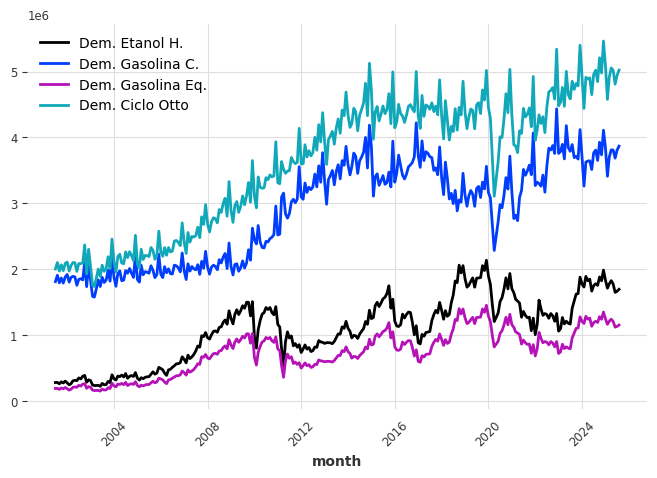

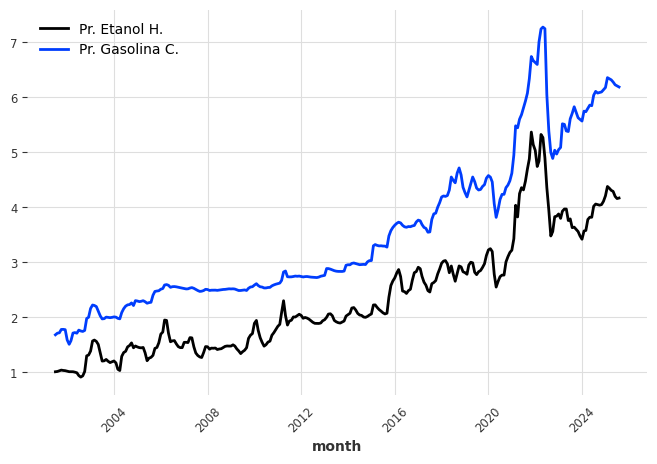

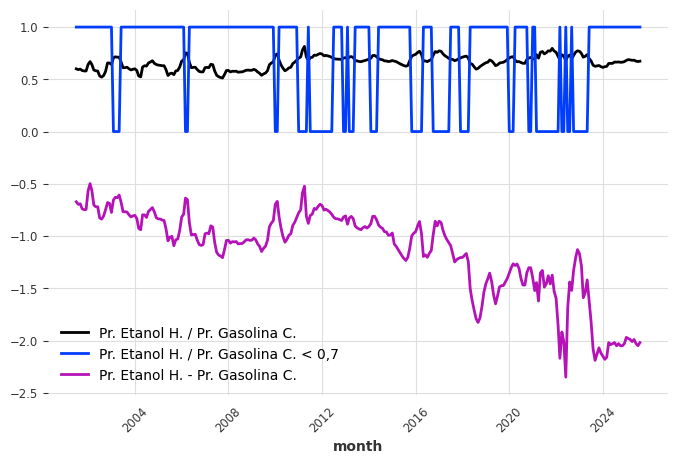

In [6]:
d_etanol_hid = TimeSeries.from_dataframe(df, "month", "Dem. Etanol H.", freq='MS')
d_gasolina_com = TimeSeries.from_dataframe(df, "month", "Dem. Gasolina C.", freq='MS')
d_gasolina_eq = TimeSeries.from_dataframe(df, "month", "Dem. Gasolina Eq.", freq='MS')
d_ciclo_otto = TimeSeries.from_dataframe(df, "month", "Dem. Ciclo Otto", freq='MS')
p_etanol_hid = TimeSeries.from_dataframe(df, "month", "Pr. Etanol H.", freq='MS')
p_gasolina_com = TimeSeries.from_dataframe(df, "month", "Pr. Gasolina C.", freq='MS')
p_r_etanol_gasolina = TimeSeries.from_dataframe(df, "month", "Pr. Etanol H. / Pr. Gasolina C.", freq='MS')
p_r_etanol_gasolina_bool = TimeSeries.from_dataframe(df, "month", "Pr. Etanol H. / Pr. Gasolina C. < 0,7", freq='MS')
p_d_etanol_gasolina = TimeSeries.from_dataframe(df, "month", "Pr. Etanol H. - Pr. Gasolina C.", freq='MS')

# Datas de início e fim da série completa
start_date = d_etanol_hid.start_time()
end_date = d_etanol_hid.end_time()

# Data final para treino+validação (dez/2024)
val_end = pd.Timestamp("2024-12-31")

# Série até dez/2024
train_val_series = d_etanol_hid.slice(start_date, val_end)

# Calcular índice de corte 70% treino / 30% validação
train_len = int(len(train_val_series) * 0.7)

# Datas correspondentes ao corte
train_start = train_val_series.start_time()
train_end = train_val_series.time_index[train_len - 1]  # último ponto do treino
VAL_START = train_end + pd.offsets.MonthBegin(1)        # mês seguinte
TEST_START = pd.Timestamp("2025-01-01")

plot_series(
    [
        d_etanol_hid,
        d_gasolina_com,
        d_gasolina_eq,
        d_ciclo_otto,
    ],
    format_index = "%Y"
)
plot_series(
    [
        p_etanol_hid,
        p_gasolina_com,
    ],
    format_index = "%Y"
)

plot_series(
    [
        p_r_etanol_gasolina,
        p_r_etanol_gasolina_bool,
        p_d_etanol_gasolina,
    ],
    format_index = "%Y"
)

## Divisão dos conjuntos em treino, validação e teste

In [7]:
train, val, test = d_etanol_hid.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)
train_d_gasolina, val_d_gasolina, test_d_gasolina = d_gasolina_com.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)
train_d_gasolina_eq, val_d_gasolina_eq, test_d_gasolina_eq = d_gasolina_eq.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)
train_d_ciclo_otto, val_d_ciclo_otto, test_d_ciclo_otto = d_ciclo_otto.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)
train_p_etanol, val_p_etanol, test_p_etanol = p_etanol_hid.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)
train_p_gasolina, val_p_gasolina, test_p_gasolina = p_gasolina_com.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)
train_p_r_etanol_gasolina, val_p_r_etanol_gasolina, test_p_r_etanol_gasolina = p_r_etanol_gasolina.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)
train_p_d_etanol_gasolina, val_p_d_etanol_gasolina, test_p_d_etanol_gasolina = p_d_etanol_gasolina.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)
train_p_r_etanol_gasolina_bool, val_p_r_etanol_gasolina_bool, test_p_r_etanol_gasolina_bool = p_r_etanol_gasolina_bool.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)

print(
    f"Treinamento: {train.time_index[0].strftime(DATE_FORMAT_STRING)} - {train.time_index[- 1].strftime(DATE_FORMAT_STRING)}"
)
print(
    f"Validação  : {val.time_index[0].strftime(DATE_FORMAT_STRING)} - {val.time_index[-1].strftime(DATE_FORMAT_STRING)}"
)
print(
    f"Teste      : {test.time_index[0].strftime(DATE_FORMAT_STRING)} - {test.time_index[-1].strftime(DATE_FORMAT_STRING)}"
)

Treinamento: 01/07/2001 - 01/11/2017
Validação  : 01/12/2017 - 01/12/2024
Teste      : 01/01/2025 - 01/08/2025


## Tratamento de dados - Série original

#### Verificação da sazonalidade

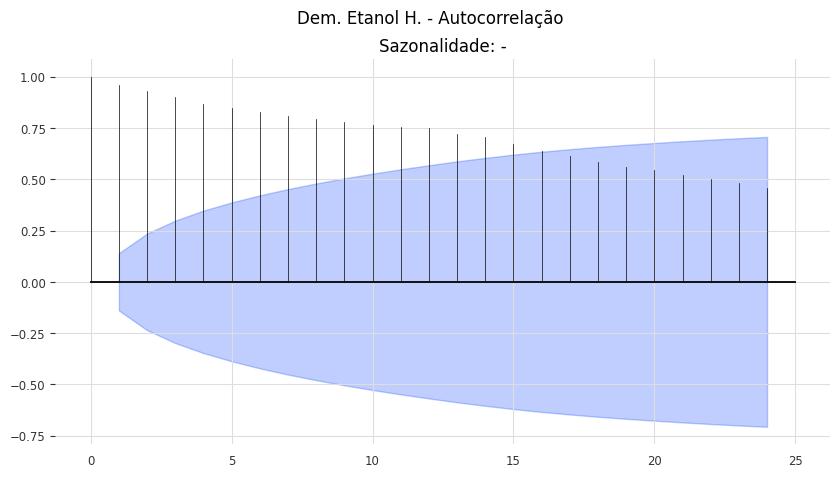

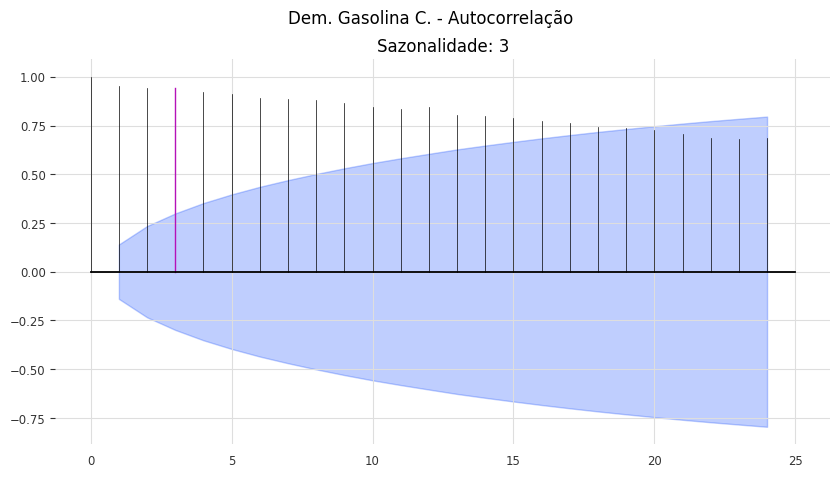

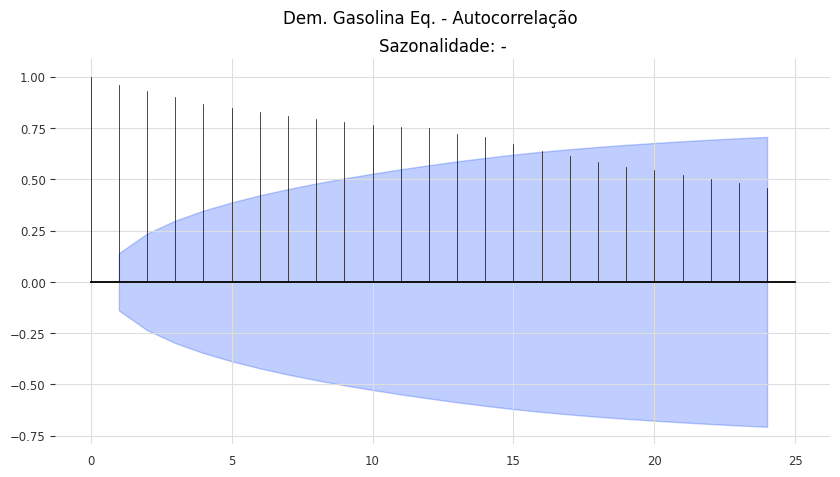

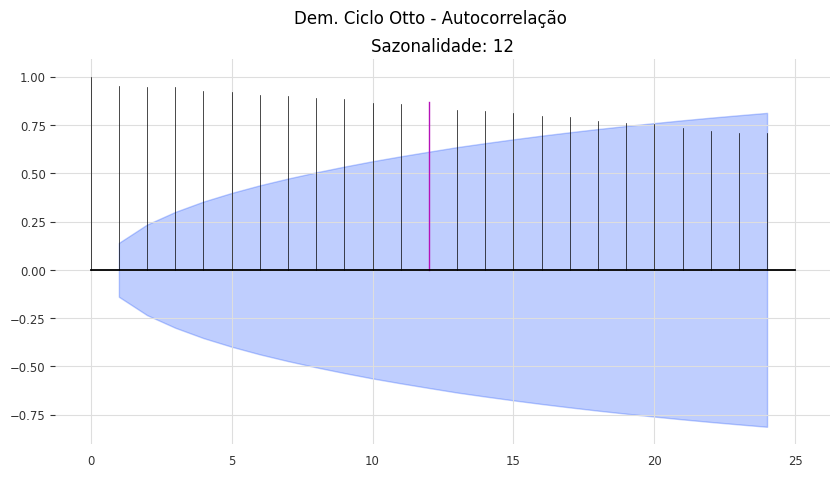

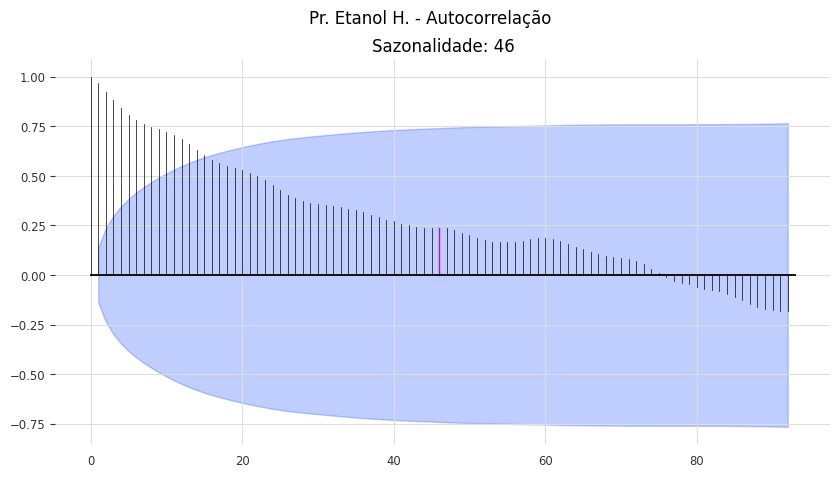

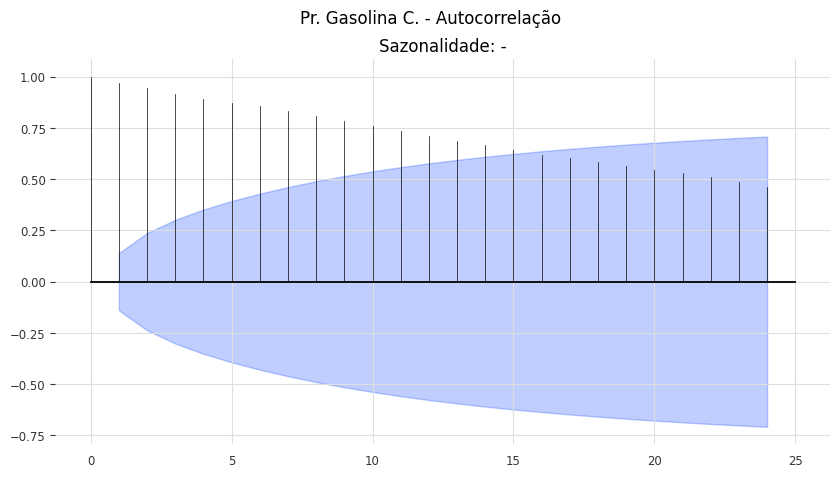

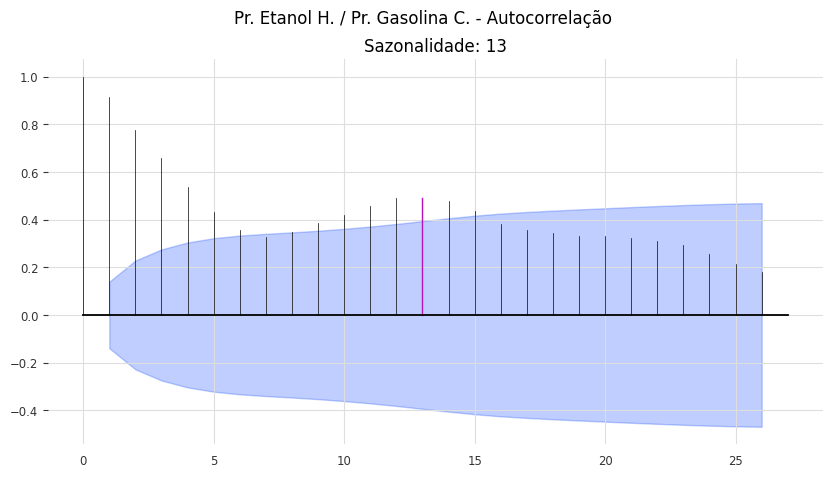

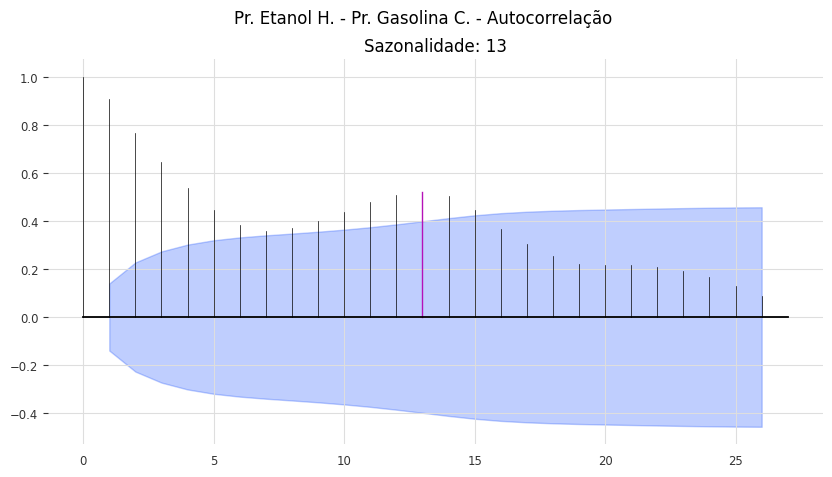

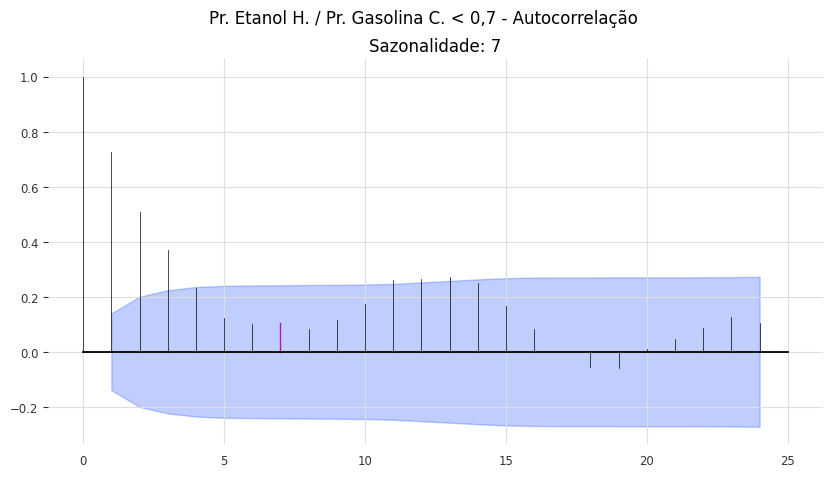

In [8]:
train.plot_acf()
train_d_gasolina.plot_acf()
train_d_gasolina_eq.plot_acf()
train_d_ciclo_otto.plot_acf()
train_p_etanol.plot_acf()
train_p_gasolina.plot_acf()
train_p_r_etanol_gasolina.plot_acf()
train_p_d_etanol_gasolina.plot_acf()
train_p_r_etanol_gasolina_bool.plot_acf()

#### Verificação de ciclos

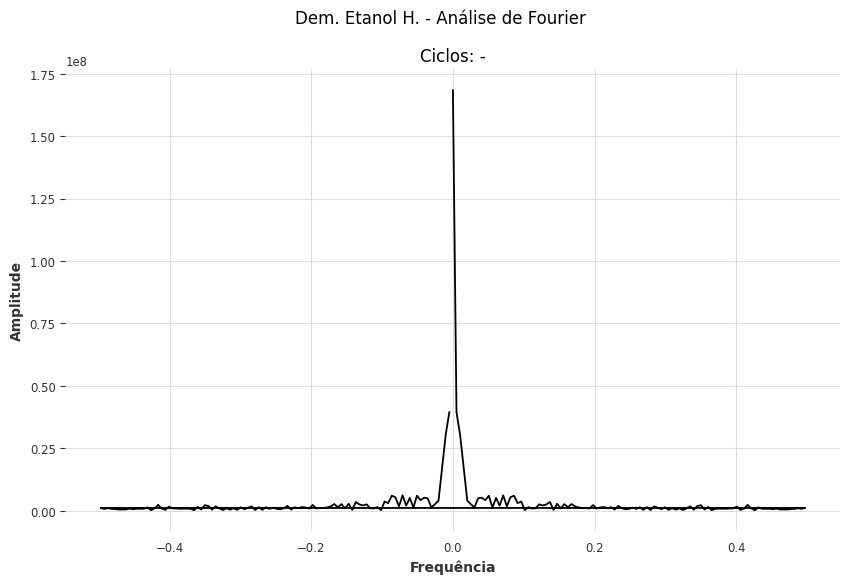

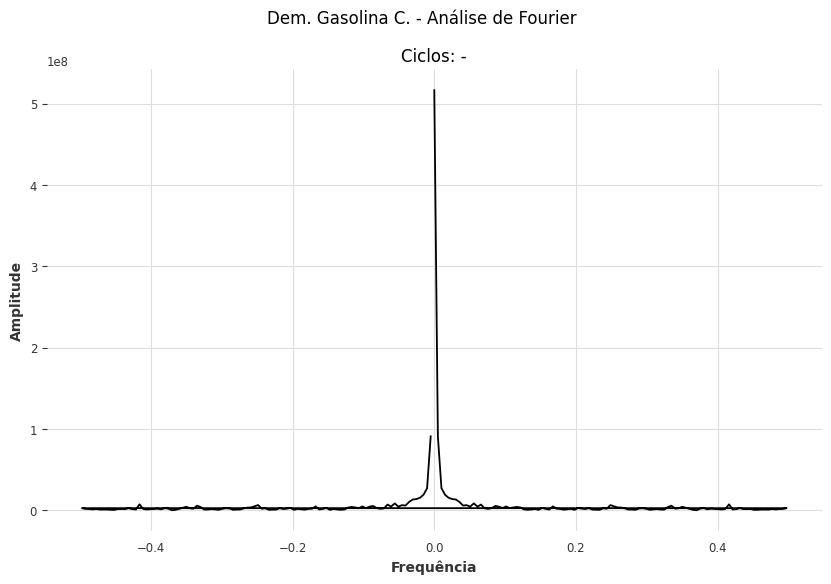

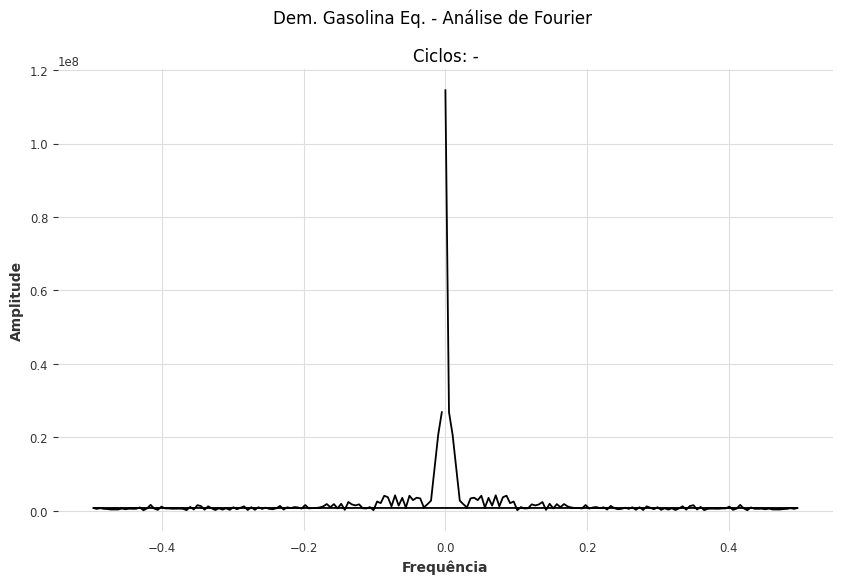

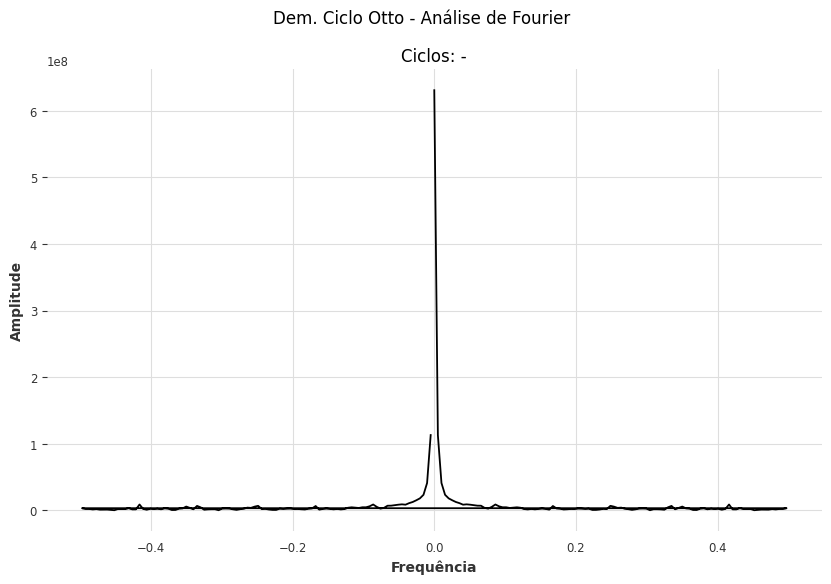

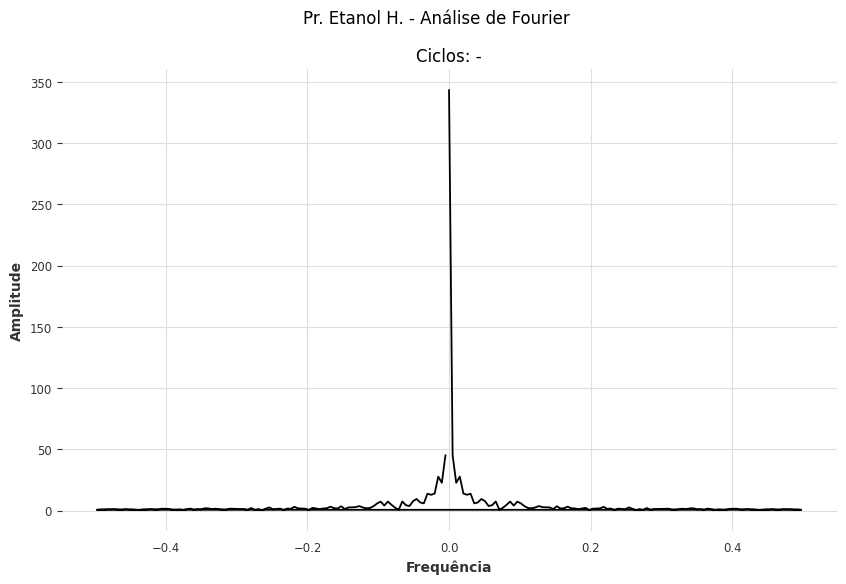

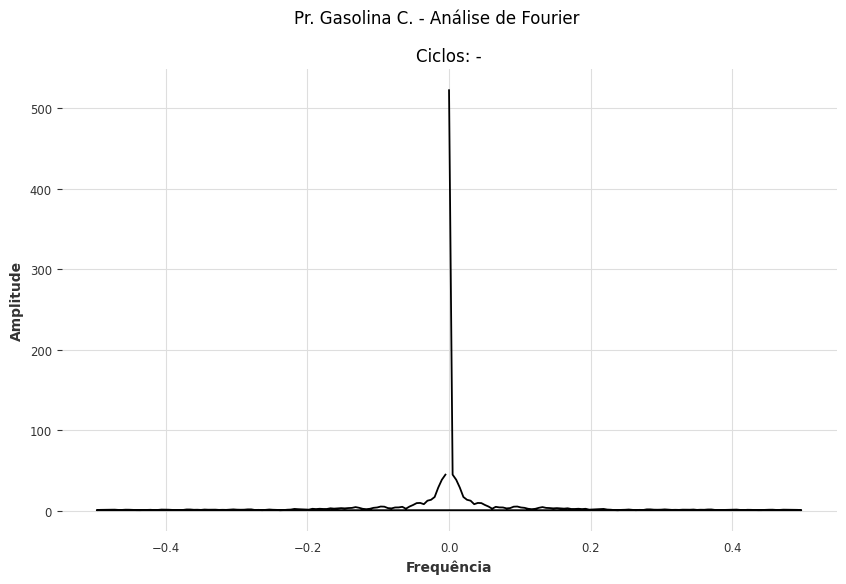

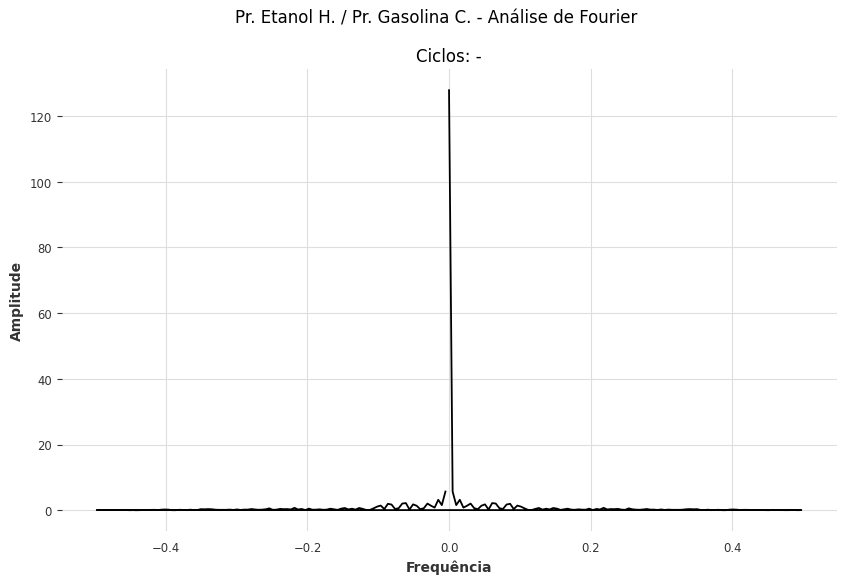

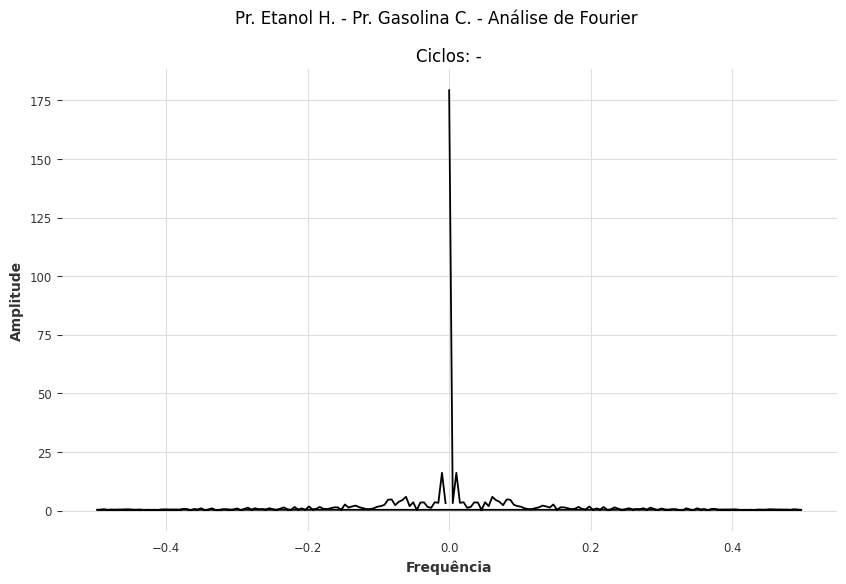

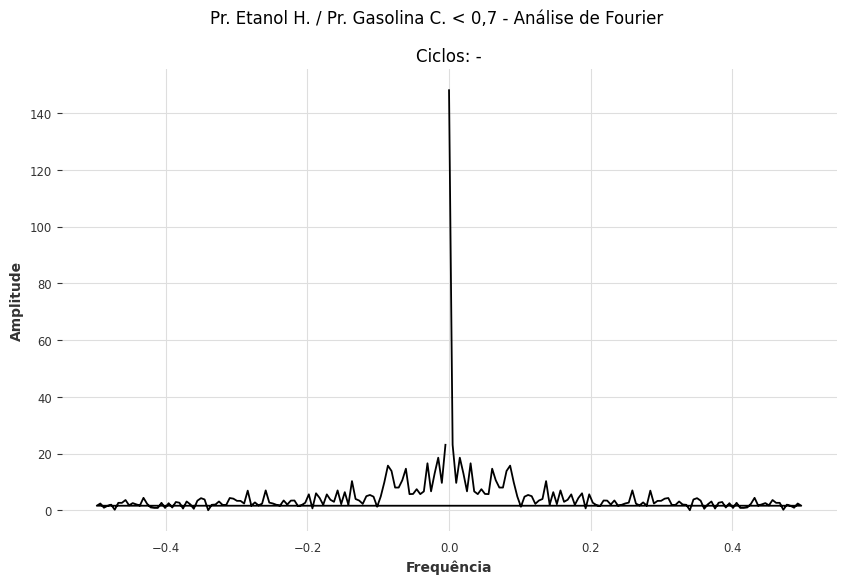

In [9]:
train.plot_fourier_analisys()
train_d_gasolina.plot_fourier_analisys()
train_d_gasolina_eq.plot_fourier_analisys()
train_d_ciclo_otto.plot_fourier_analisys()
train_p_etanol.plot_fourier_analisys()
train_p_gasolina.plot_fourier_analisys()
train_p_r_etanol_gasolina.plot_fourier_analisys()
train_p_d_etanol_gasolina.plot_fourier_analisys()
train_p_r_etanol_gasolina_bool.plot_fourier_analisys()

#### Coeficiente de Hurst

In [10]:
hurst = Hurst()

H, HDescription = hurst.calculate(train)
print("Coeficiente de Hurst = {:.2f} - {}".format(H, HDescription))

Coeficiente de Hurst = 0.39 - Anti-persistente


#### Matriz de correlação

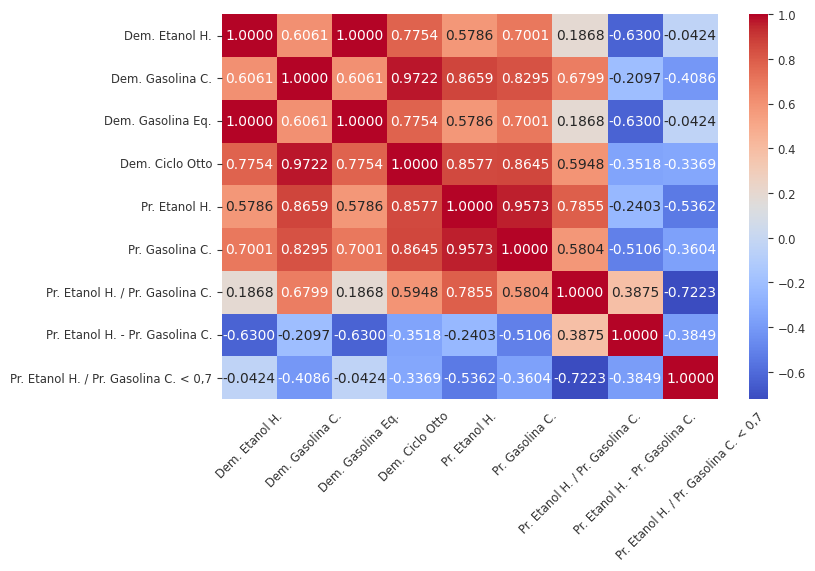

array([[ 1.        ,  0.60612157,  1.        ,  0.77538748,  0.57859148,
         0.70008453,  0.18684387, -0.63001784, -0.04239067],
       [ 0.60612157,  1.        ,  0.60612157,  0.97224517,  0.86592871,
         0.82946634,  0.67994008, -0.20970602, -0.40858251],
       [ 1.        ,  0.60612157,  1.        ,  0.77538748,  0.57859148,
         0.70008453,  0.18684387, -0.63001784, -0.04239067],
       [ 0.77538748,  0.97224517,  0.77538748,  1.        ,  0.85770108,
         0.86448982,  0.5948    , -0.35182039, -0.33686367],
       [ 0.57859148,  0.86592871,  0.57859148,  0.85770108,  1.        ,
         0.95732732,  0.78545719, -0.24027746, -0.53623334],
       [ 0.70008453,  0.82946634,  0.70008453,  0.86448982,  0.95732732,
         1.        ,  0.58037896, -0.51056342, -0.36038327],
       [ 0.18684387,  0.67994008,  0.18684387,  0.5948    ,  0.78545719,
         0.58037896,  1.        ,  0.38750511, -0.72228002],
       [-0.63001784, -0.20970602, -0.63001784, -0.35182039, -0

In [11]:
plot_correlation_matrix([
    train,
    train_d_gasolina,
    train_d_gasolina_eq,
    train_d_ciclo_otto,
    train_p_etanol,
    train_p_gasolina,
    train_p_r_etanol_gasolina,
    train_p_d_etanol_gasolina,
    train_p_r_etanol_gasolina_bool,
], annot = True, fmt=".4f", )

### Aplicando o filtro de média móvel

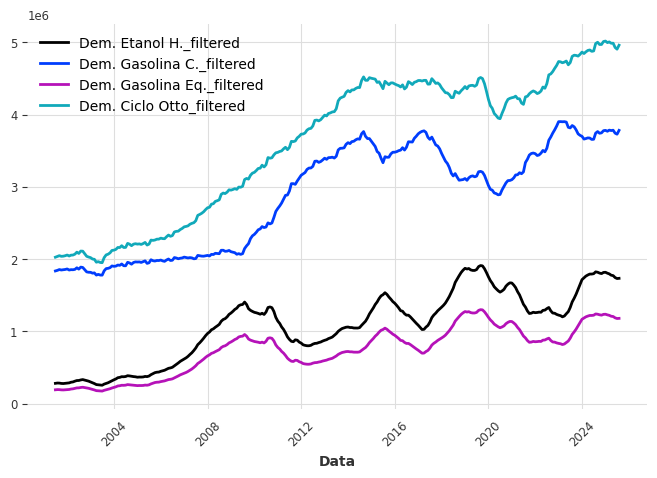

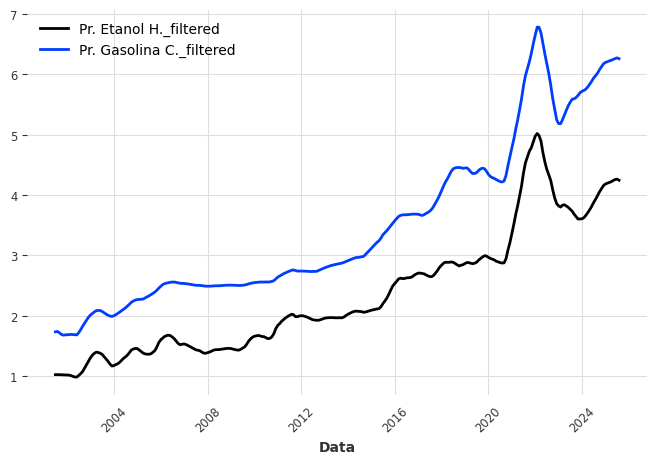

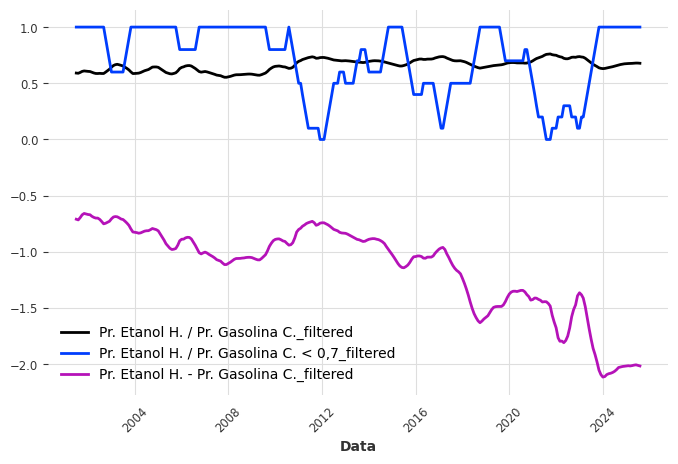

In [12]:
d_etanol_hid_filtered = d_etanol_hid.filter()[0]
d_gasolina_com_filtered = d_gasolina_com.filter()[0]
d_gasolina_eq_filtered = d_gasolina_eq.filter()[0]
d_ciclo_otto_filtered = d_ciclo_otto.filter()[0]
p_etanol_hid_filtered = p_etanol_hid.filter()[0]
p_gasolina_com_filtered = p_gasolina_com.filter()[0]
p_r_etanol_gasolina_filtered = p_r_etanol_gasolina.filter()[0]
p_r_etanol_gasolina_bool_filtered = p_r_etanol_gasolina_bool.filter()[0]
p_d_etanol_gasolina_filtered = p_d_etanol_gasolina.filter()[0]

plot_series(
    [
        d_etanol_hid_filtered,
        d_gasolina_com_filtered,
        d_gasolina_eq_filtered,
        d_ciclo_otto_filtered,
    ],
    format_index = "%Y"
)
plot_series(
    [
        p_etanol_hid_filtered,
        p_gasolina_com_filtered,
    ],
    format_index = "%Y"
)

plot_series(
    [
        p_r_etanol_gasolina_filtered,
        p_r_etanol_gasolina_bool_filtered,
        p_d_etanol_gasolina_filtered,
    ],
    format_index = "%Y"
)

## Tratamento de dados - Série sem tendência

In [13]:
# --- Supondo que sua classe Detrend já está definida ---
scaler = Detrend()

# --- Função auxiliar para detrend e reconstruir TimeSeries ---
def detrend_series(train, val, test, series):
    # Nome do componente original
    component_name = series.columns[0]
    
    scaler = Detrend()
    
    # Extrair numpy univariado
    train_np = train.univariate_component(0).values()[:,0]
    val_np = val.univariate_component(0).values()[:,0]
    test_np = test.univariate_component(0).values()[:,0]
    series_np = series.univariate_component(0).values()[:,0]

    # Fit e transform no treino
    train_detrend_np = scaler.fit_transform(train_np)
    val_detrend_np = scaler.transform(val_np)
    test_detrend_np = scaler.transform(test_np)
    series_detrend_np = scaler.transform(series_np)

    # Reconstruir TimeSeries mantendo time_index
    train_detrend = TimeSeries.from_times_and_values(train.time_index, train_detrend_np.reshape(-1,1), columns=[component_name])
    val_detrend = TimeSeries.from_times_and_values(val.time_index, val_detrend_np.reshape(-1,1), columns=[component_name])
    test_detrend = TimeSeries.from_times_and_values(test.time_index, test_detrend_np.reshape(-1,1), columns=[component_name])
    series_detrend = TimeSeries.from_times_and_values(series.time_index, series_detrend_np.reshape(-1,1), columns=[component_name])

    return train_detrend, val_detrend, test_detrend, series_detrend


train_detrend, val_detrend, test_detrend, d_etanol_hid_detrend = detrend_series(train, val, test, d_etanol_hid)
train_d_gasolina_detrend, val_d_gasolina_detrend, test_d_gasolina_detrend, d_gasolina_com_detrend = detrend_series(train_d_gasolina, val_d_gasolina, test_d_gasolina, d_gasolina_com)
train_d_gasolina_eq_detrend, val_d_gasolina_eq_detrend, test_d_gasolina_eq_detrend, d_gasolina_eq_detrend = detrend_series(train_d_gasolina_eq, val_d_gasolina_eq, test_d_gasolina_eq, d_gasolina_eq)
train_d_ciclo_otto_detrend, val_d_ciclo_otto_detrend, test_d_ciclo_otto_detrend, d_ciclo_otto_detrend = detrend_series(train_d_ciclo_otto, val_d_ciclo_otto, test_d_ciclo_otto, d_ciclo_otto)
train_p_etanol_detrend, val_p_etanol_detrend, test_p_etanol_detrend, p_etanol_hid_detrend = detrend_series(train_p_etanol, val_p_etanol, test_p_etanol, p_etanol_hid)
train_p_gasolina_detrend, val_p_gasolina_detrend, test_p_gasolina_detrend, p_gasolina_com_detrend = detrend_series(train_p_gasolina, val_p_gasolina, test_p_gasolina, p_gasolina_com)
train_p_r_etanol_gasolina_detrend, val_p_r_etanol_gasolina_detrend, test_p_r_etanol_gasolina_detrend, p_r_etanol_gasolina_detrend = detrend_series(train_p_r_etanol_gasolina, val_p_r_etanol_gasolina, test_p_r_etanol_gasolina, p_r_etanol_gasolina)
train_p_d_etanol_gasolina_detrend, val_p_d_etanol_gasolina_detrend, test_p_d_etanol_gasolina_detrend, p_d_etanol_gasolina_detrend = detrend_series(train_p_d_etanol_gasolina, val_p_d_etanol_gasolina, test_p_d_etanol_gasolina, p_d_etanol_gasolina)
train_p_r_etanol_gasolina_bool_detrend, val_p_r_etanol_gasolina_bool_detrend, test_p_r_etanol_gasolina_bool_detrend, p_r_etanol_gasolina_bool_detrend = detrend_series(train_p_r_etanol_gasolina_bool, val_p_r_etanol_gasolina_bool, test_p_r_etanol_gasolina_bool, p_r_etanol_gasolina_bool)

#### Verificação da sazonalidade

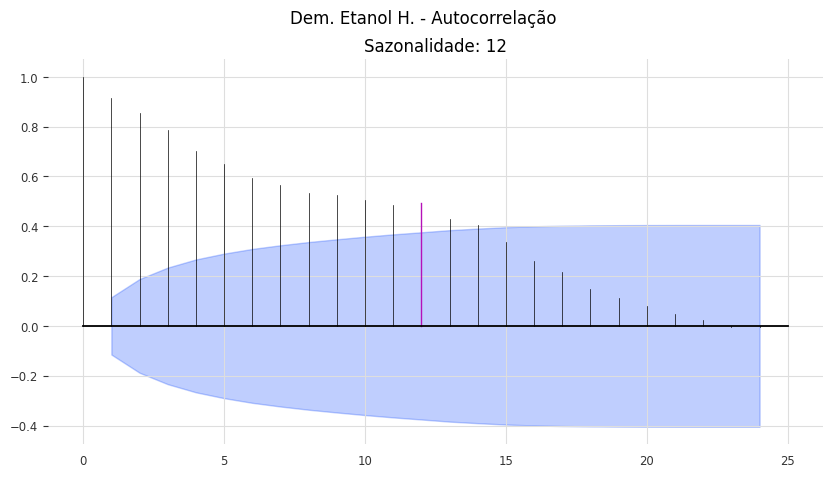

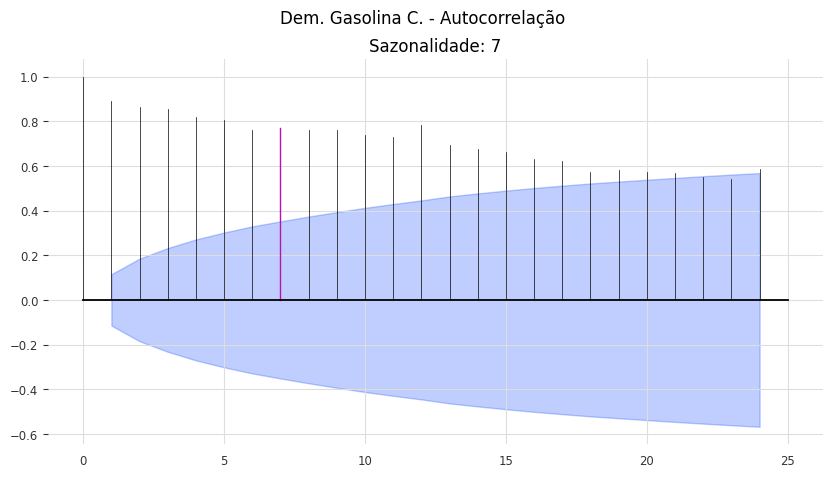

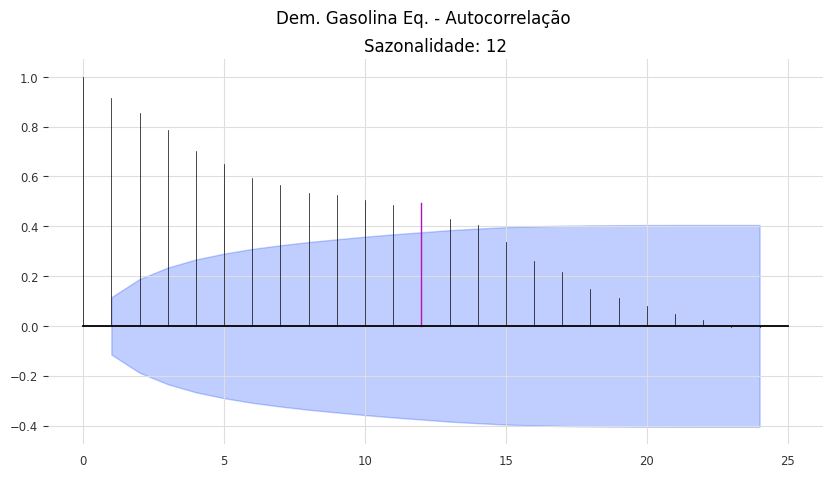

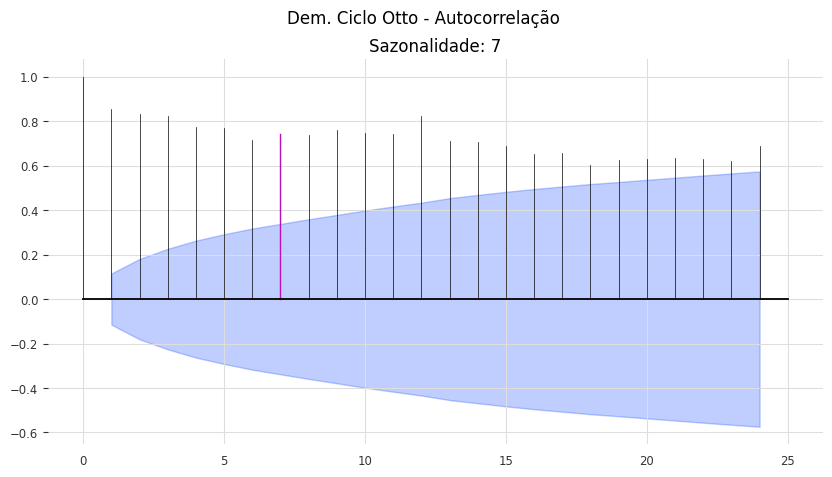

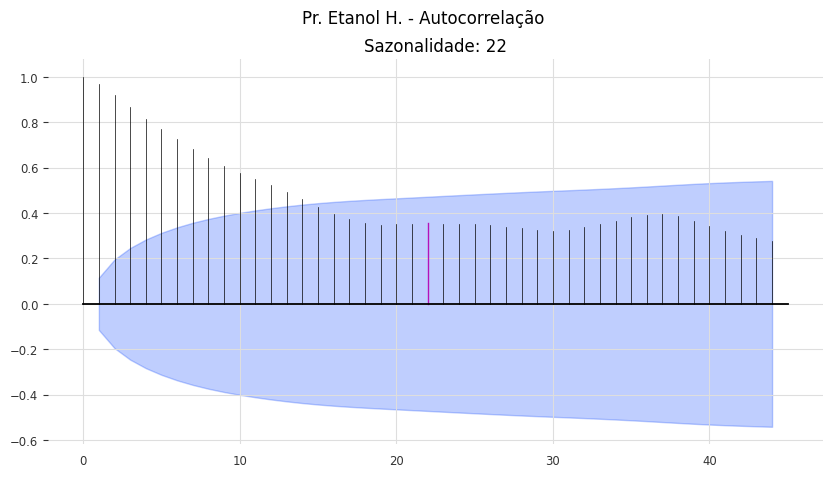

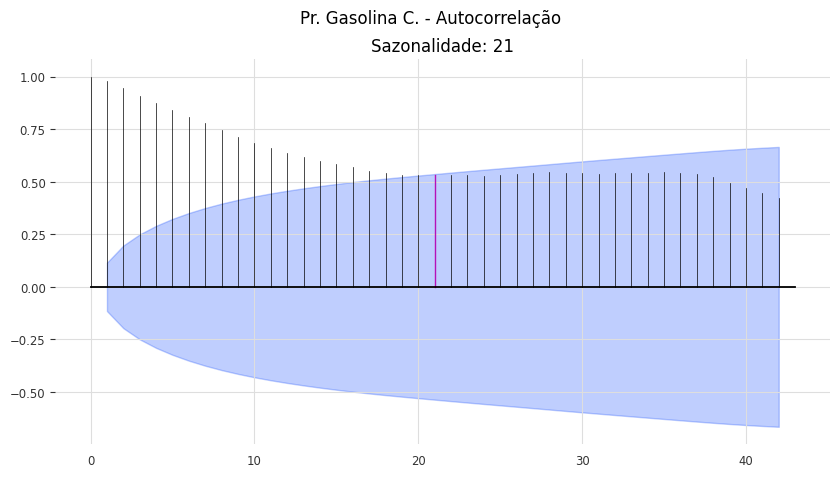

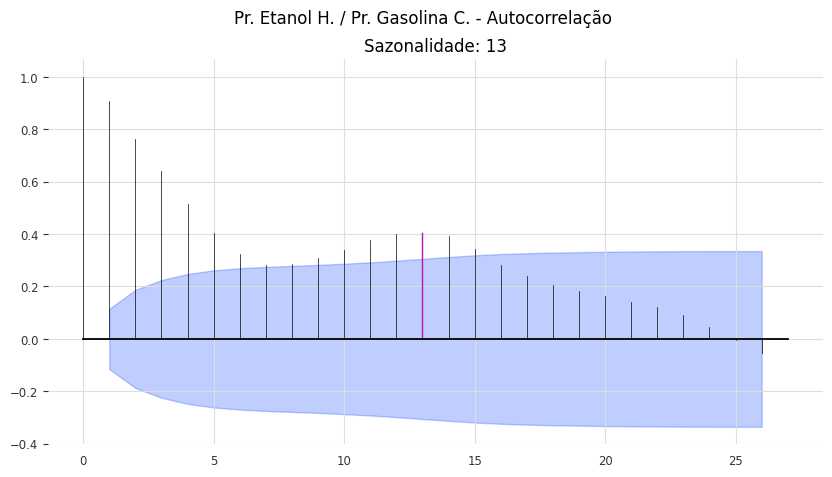

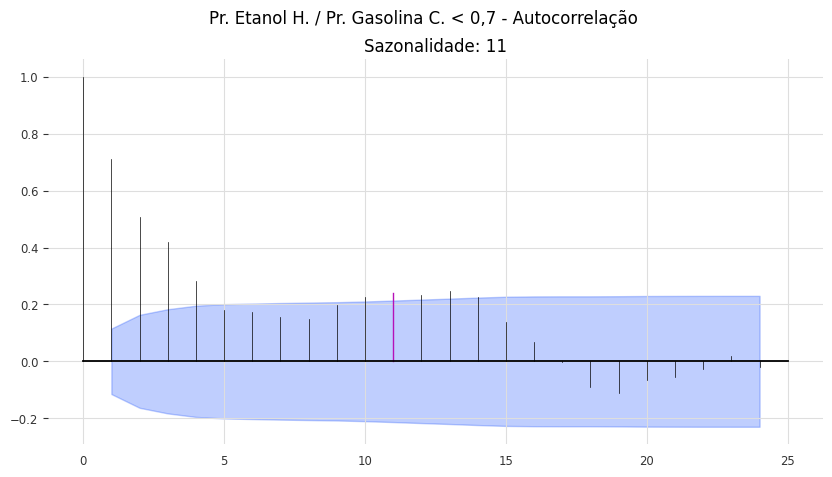

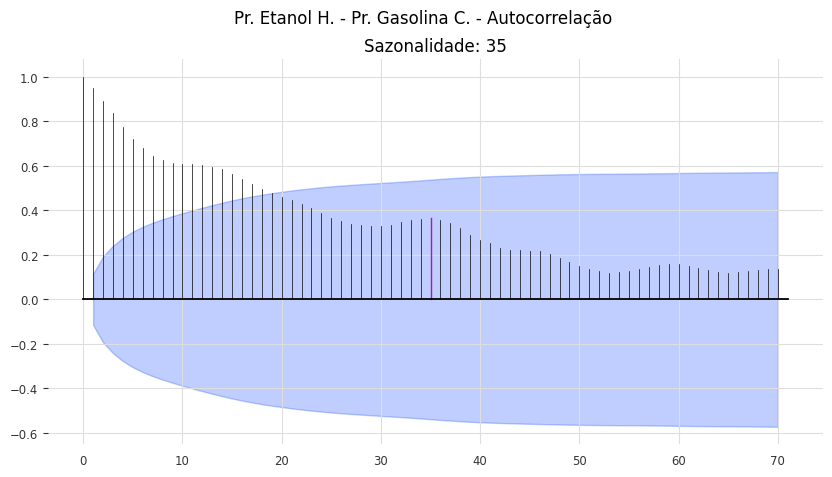

In [14]:
d_etanol_hid_detrend.plot_acf()
d_gasolina_com_detrend.plot_acf()
d_gasolina_eq_detrend.plot_acf()
d_ciclo_otto_detrend.plot_acf()
p_etanol_hid_detrend.plot_acf()
p_gasolina_com_detrend.plot_acf()
p_r_etanol_gasolina_detrend.plot_acf()
p_r_etanol_gasolina_bool_detrend.plot_acf()
p_d_etanol_gasolina_detrend.plot_acf()

#### Verificação de ciclos

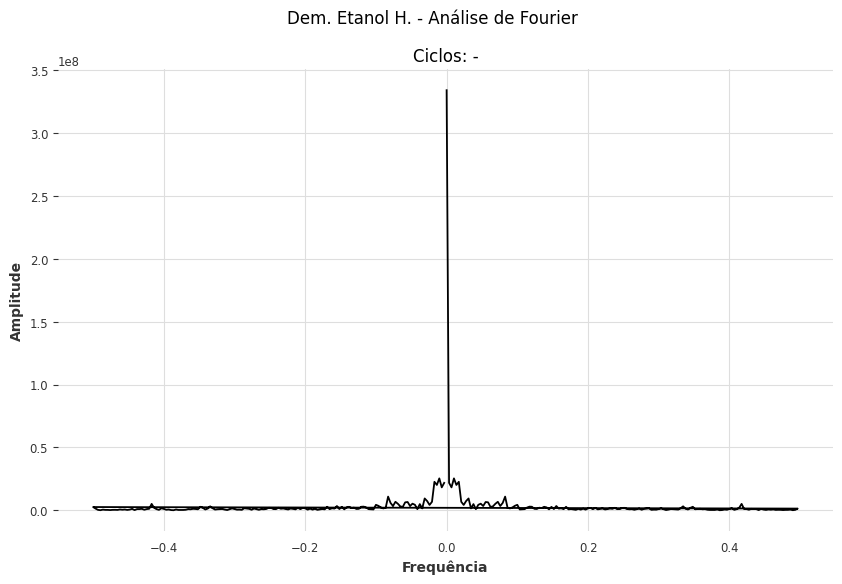

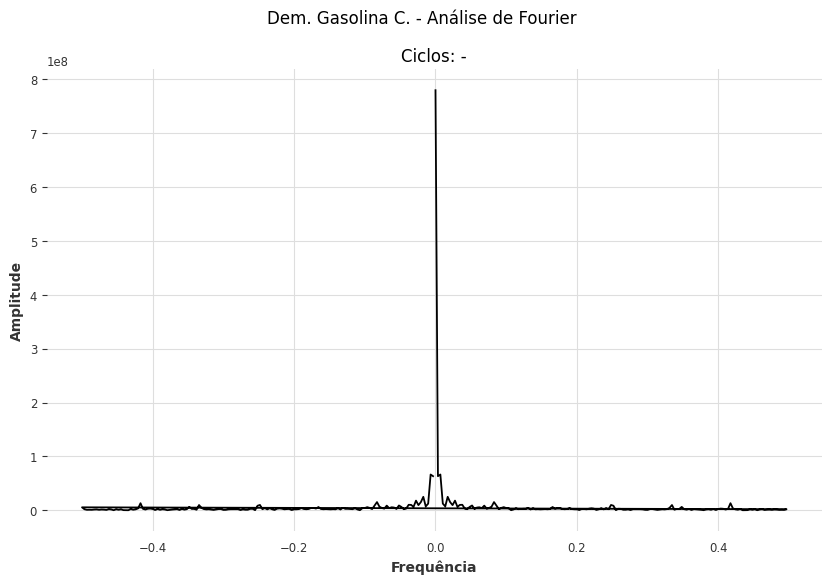

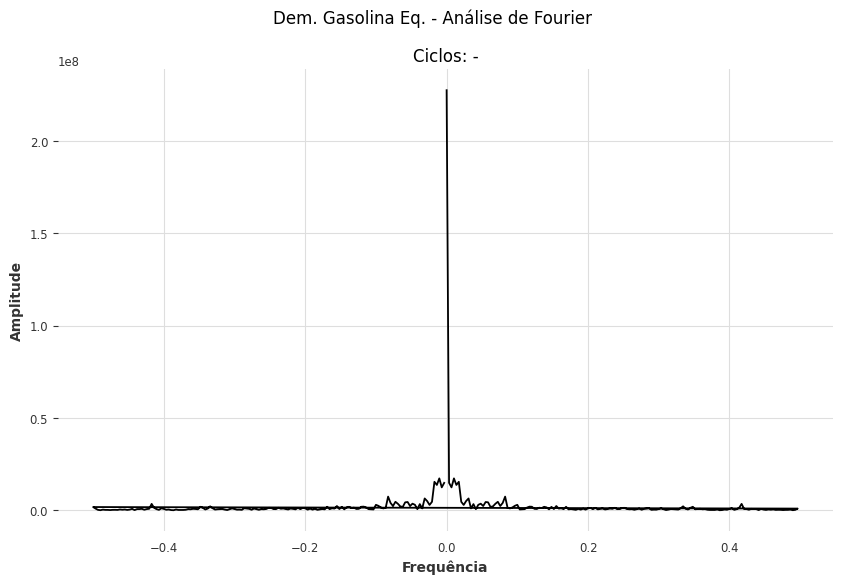

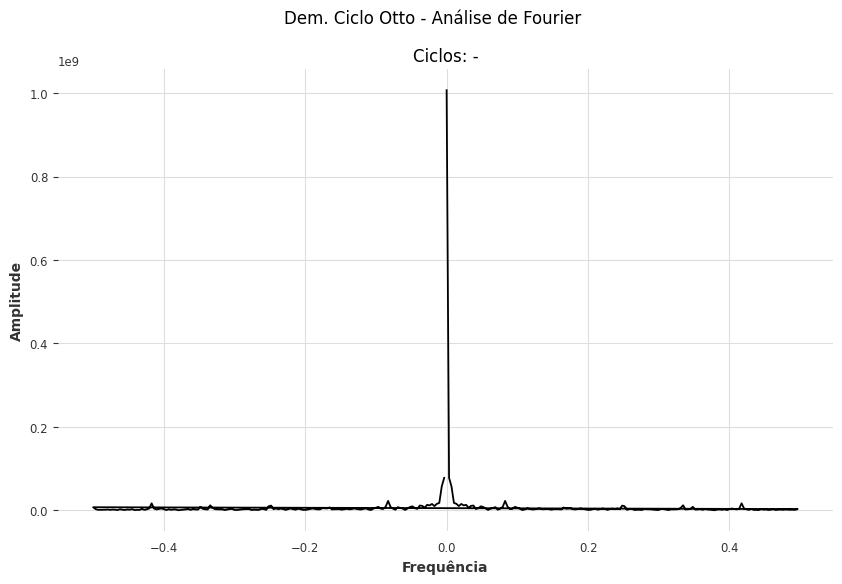

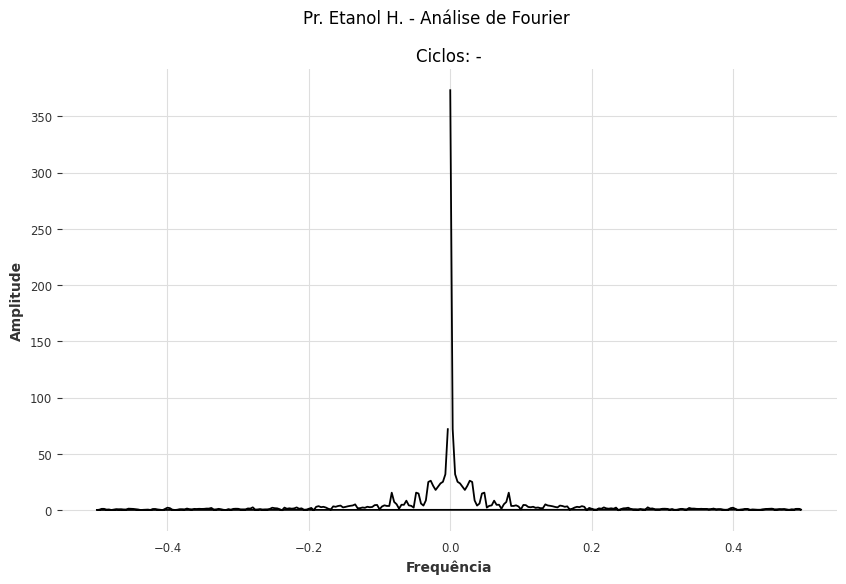

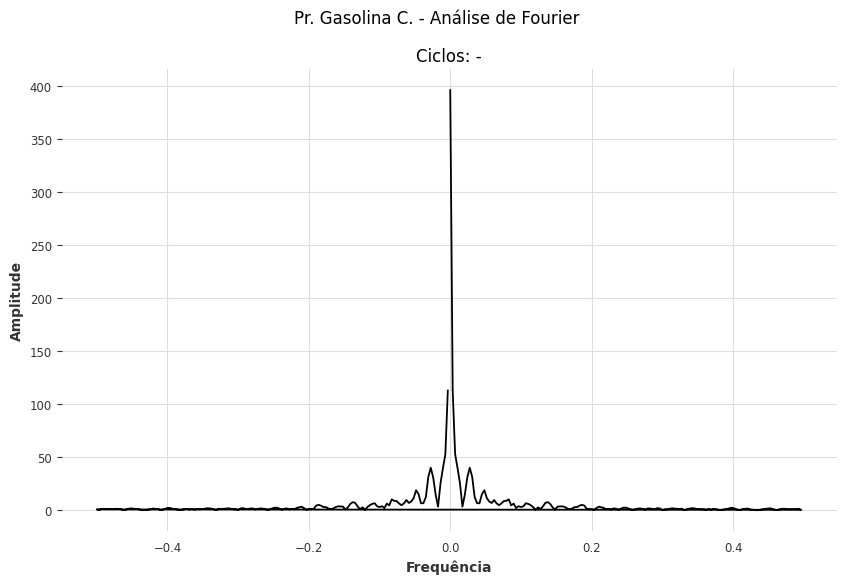

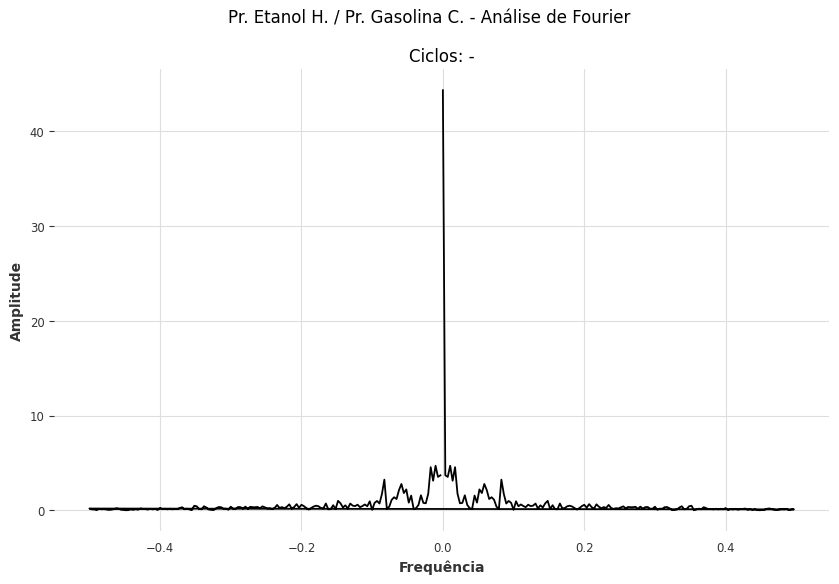

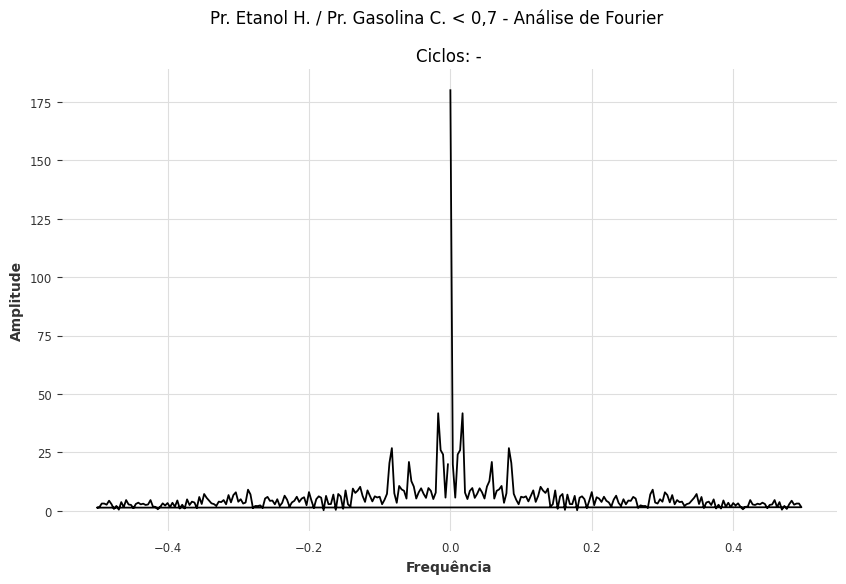

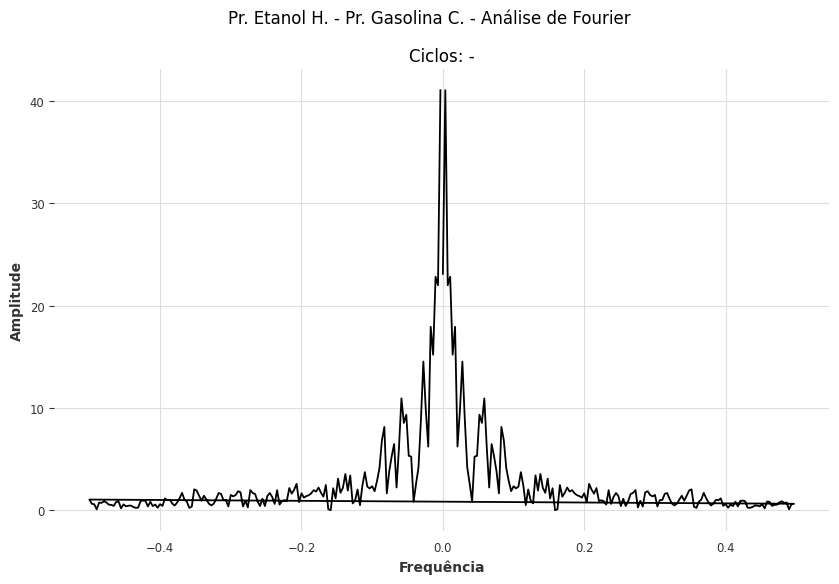

In [15]:
d_etanol_hid_detrend.plot_fourier_analisys()
d_gasolina_com_detrend.plot_fourier_analisys()
d_gasolina_eq_detrend.plot_fourier_analisys()
d_ciclo_otto_detrend.plot_fourier_analisys()
p_etanol_hid_detrend.plot_fourier_analisys()
p_gasolina_com_detrend.plot_fourier_analisys()
p_r_etanol_gasolina_detrend.plot_fourier_analisys()
p_r_etanol_gasolina_bool_detrend.plot_fourier_analisys()
p_d_etanol_gasolina_detrend.plot_fourier_analisys()

#### Coeficiente de Hurst

In [16]:
hurst = Hurst()

H, HDescription = hurst.calculate(d_etanol_hid_detrend)
print("Coeficiente de Hurst = {:.2f} - {}".format(H, HDescription))

Coeficiente de Hurst = 0.41 - Anti-persistente


#### Matriz de correlação

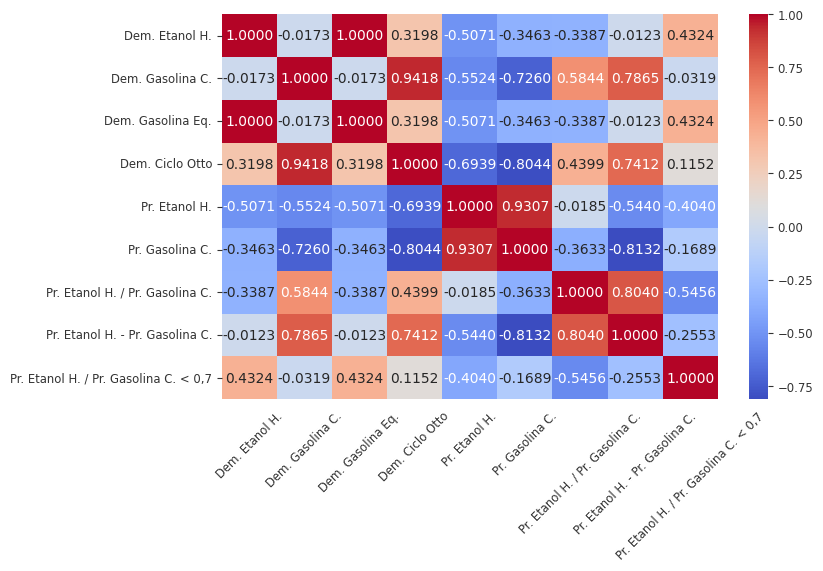

array([[ 1.        , -0.01731909,  1.        ,  0.31977174, -0.50707293,
        -0.34632391, -0.33871406, -0.01233782,  0.43236216],
       [-0.01731909,  1.        , -0.01731909,  0.94181434, -0.5523929 ,
        -0.7259745 ,  0.58441698,  0.78652357, -0.03185837],
       [ 1.        , -0.01731909,  1.        ,  0.31977174, -0.50707293,
        -0.34632391, -0.33871406, -0.01233782,  0.43236216],
       [ 0.31977174,  0.94181434,  0.31977174,  1.        , -0.69393759,
        -0.80438865,  0.43994478,  0.74119085,  0.11516306],
       [-0.50707293, -0.5523929 , -0.50707293, -0.69393759,  1.        ,
         0.93071158, -0.01850313, -0.54398682, -0.40398168],
       [-0.34632391, -0.7259745 , -0.34632391, -0.80438865,  0.93071158,
         1.        , -0.3632795 , -0.8131967 , -0.16891193],
       [-0.33871406,  0.58441698, -0.33871406,  0.43994478, -0.01850313,
        -0.3632795 ,  1.        ,  0.80397474, -0.54561149],
       [-0.01233782,  0.78652357, -0.01233782,  0.74119085, -0

In [17]:
plot_correlation_matrix([
    d_etanol_hid_detrend,
    d_gasolina_com_detrend,
    d_gasolina_eq_detrend,
    d_ciclo_otto_detrend,
    p_etanol_hid_detrend,
    p_gasolina_com_detrend,
    p_r_etanol_gasolina_detrend,
    p_d_etanol_gasolina_detrend,
    p_r_etanol_gasolina_bool,
], annot = True, fmt=".4f", )

### Aplicando o filtro de média móvel

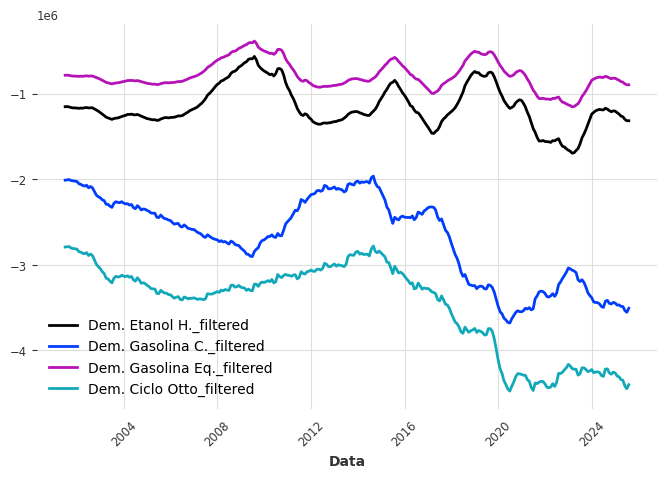

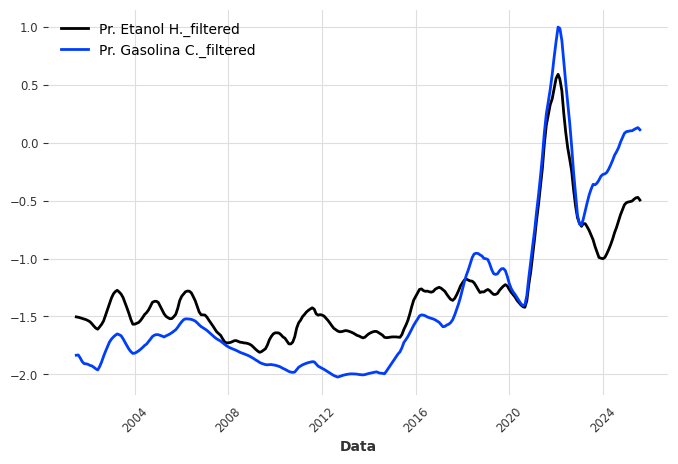

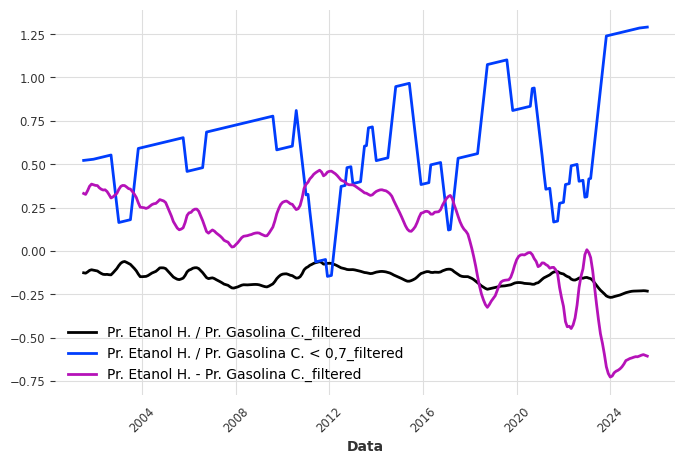

In [18]:
d_etanol_hid_detrend_filtered = d_etanol_hid_detrend.filter()[0]
d_gasolina_com_detrend_filtered = d_gasolina_com_detrend.filter()[0]
d_gasolina_eq_detrend_filtered = d_gasolina_eq_detrend.filter()[0]
d_ciclo_otto_detrend_filtered = d_ciclo_otto_detrend.filter()[0]
p_etanol_hid_detrend_filtered = p_etanol_hid_detrend.filter()[0]
p_gasolina_com_detrend_filtered = p_gasolina_com_detrend.filter()[0]
p_r_etanol_gasolina_detrend_filtered = p_r_etanol_gasolina_detrend.filter()[0]
p_r_etanol_gasolina_bool_detrend_filtered = p_r_etanol_gasolina_bool_detrend.filter()[0]
p_d_etanol_gasolina_detrend_filtered = p_d_etanol_gasolina_detrend.filter()[0]

plot_series(
    [
        d_etanol_hid_detrend_filtered,
        d_gasolina_com_detrend_filtered,
        d_gasolina_eq_detrend_filtered,
        d_ciclo_otto_detrend_filtered,
    ],
    format_index = "%Y"
)
plot_series(
    [
        p_etanol_hid_detrend_filtered,
        p_gasolina_com_detrend_filtered,
    ],
    format_index = "%Y"
)

plot_series(
    [
        p_r_etanol_gasolina_detrend_filtered,
        p_r_etanol_gasolina_bool_detrend_filtered,
        p_d_etanol_gasolina_detrend_filtered,
    ],
    format_index = "%Y"
)

# Treinando o modelo

## Arima

### Original

In [ ]:
scaler = Scaler()
train_scaled = scaler.fit_transform(train)
val_scaled = scaler.transform(val)
d_etanol_hid_scaled = scaler.transform(d_etanol_hid)

model_name = 'ARIMA'
series_train=['train_scaled']
for p in range(12, 30, 4):
    for d in range(1, 3):
        for q in range(0, 5, 2):
            for s in range(0, 10, 3):
                try:
                    model_run, existing = create_or_get_model_run(
                        model_name=model_name,
                        parametros={                       
                            'p': p,
                            'd': d,
                            'q': q,
                            's': s
                        },
                        series_train=series_train
                    )
                    if existing:
                        continue
                    model = ARIMA(
                        p=p,
                        d=d,
                        seasonal_order=(
                            0,
                            0,
                            q,
                            s
                        ),
                    )
                    model.fit(train_scaled)
                    pred_series, mape_arima, sle_arima = eval_model(
                        model,
                        len(val_scaled),
                        d_etanol_hid_scaled.slice(train.start_time(), val.end_time()),
                        val_scaled,
                        returned = ['PREDICT_VALUES', 'MAPE_VAL', 'SLE_VAL'],
                        plot = False,
                    )
                    uTheil = UTheil()
                    u1_arima = uTheil.calculateU1(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
                    u2_arima = uTheil.calculateU2(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
                    print({
                        'mape': mape_arima,
                        'sle': sle_arima,
                        'u1': u1_arima,
                        'u2': u1_arima,
                        'p': p,
                        'd': d,
                        'q': q,
                        's': s,
                    })
                    metrics = {
                        'mape': mape_arima,
                        'sle': sle_arima,
                        'u1': u1_arima,
                        'u2': u1_arima,
                    }
                    update_model_metrics(model_run, **metrics)
                except:
                    pass

{'mape': np.float64(20.448656427473324), 'sle': np.float64(6.795468643077203), 'u1': np.float64(0.21423973450528203), 'u2': np.float64(0.21423973450528203), 'p': 12, 'd': 1, 'q': 0, 's': 0}
{'mape': np.float64(20.448656427473324), 'sle': np.float64(6.795468643077203), 'u1': np.float64(0.21423973450528203), 'u2': np.float64(0.21423973450528203), 'p': 12, 'd': 1, 'q': 0, 's': 3}
{'mape': np.float64(20.448656427473324), 'sle': np.float64(6.795468643077203), 'u1': np.float64(0.21423973450528203), 'u2': np.float64(0.21423973450528203), 'p': 12, 'd': 1, 'q': 0, 's': 6}
{'mape': np.float64(20.448656427473324), 'sle': np.float64(6.795468643077203), 'u1': np.float64(0.21423973450528203), 'u2': np.float64(0.21423973450528203), 'p': 12, 'd': 1, 'q': 0, 's': 9}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(20.422948472604563), 'sle': np.float64(6.813656739853509), 'u1': np.float64(0.21459801408125004), 'u2': np.float64(0.21459801408125004), 'p': 12, 'd': 1, 'q': 2, 's': 3}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(20.42866284146487), 'sle': np.float64(6.776998110705295), 'u1': np.float64(0.21315678814042543), 'u2': np.float64(0.21315678814042543), 'p': 12, 'd': 1, 'q': 2, 's': 6}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


... (123 outputs left out)

/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(19.620684121902453), 'sle': np.float64(5.333405169232321), 'u1': np.float64(0.18861963388692968), 'u2': np.float64(0.18861963388692968), 'p': 28, 'd': 1, 'q': 0, 's': 9}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(19.453767559443783), 'sle': np.float64(5.0407719109859315), 'u1': np.float64(0.18262930120768145), 'u2': np.float64(0.18262930120768145), 'p': 28, 'd': 1, 'q': 2, 's': 6}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


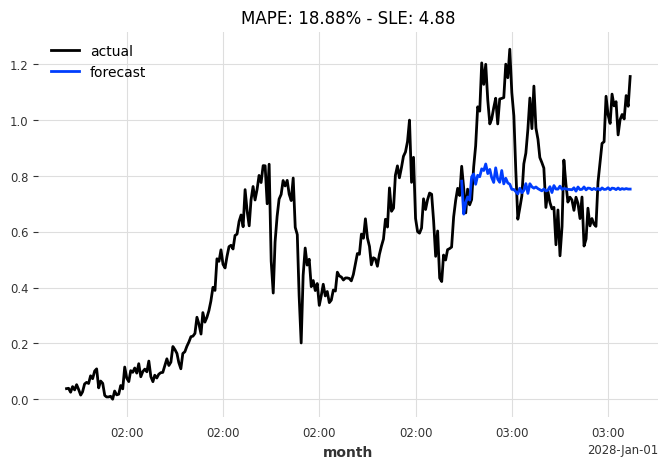

{'p': 16, 'd': 1, 'q': 4, 's': 9}


In [23]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("ARIMA", series_train=["train_scaled"], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

scaler = Scaler()
train_scaled = scaler.fit_transform(train)
val_scaled = scaler.transform(val)
d_etanol_hid_scaled = scaler.transform(d_etanol_hid)

model = ARIMA(
    p=best_model['p'],
    d=best_model['d'],
    seasonal_order=(
        0,
        0,
        best_model['q'],
        best_model['s']
    ),
)
model.fit(train_scaled)
pred_series, mape_arima, sle_arima = eval_model(
    model,
    len(val_scaled),
    d_etanol_hid_scaled.slice(train.start_time(), val.end_time()),
    val_scaled,
    returned = ['PREDICT_VALUES', 'MAPE_VAL', 'SLE_VAL'],
    plot = True,
)
uTheil = UTheil()
u1_arima = uTheil.calculateU1(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
u2_arima = uTheil.calculateU2(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
print(best_model)

### Filtrada

In [20]:
scaler = Scaler()
train_scaled = scaler.fit_transform(train)
val_scaled = scaler.transform(val)
d_etanol_hid_scaled = scaler.transform(d_etanol_hid)
d_etanol_hid_scaled = d_etanol_hid_scaled.filter()[0]
train_scaled, val_scaled, test_scaled = d_etanol_hid_scaled.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)

model_name = 'ARIMA'
series_train=['train_filtered_scaled']

for p in range(12, 30, 4):
    for d in range(1, 3):
        for q in range(0, 5, 2):
            for s in range(0, 10, 3):
                try:
                    model_run, existing = create_or_get_model_run(
                        model_name=model_name,
                        parametros={                       
                            'p': p,
                            'd': d,
                            'q': q,
                            's': s
                        },
                        series_train=series_train
                    )
                    if existing:
                        continue
                    model = ARIMA(
                        p=p,
                        d=d,
                        seasonal_order=(
                            0,
                            0,
                            q,
                            s
                        ),
                    )
                    model.fit(train_scaled)
                    pred_series, mape_arima, sle_arima = eval_model(
                        model,
                        len(val_scaled),
                        d_etanol_hid_scaled.slice(train.start_time(), val.end_time()),
                        val_scaled,
                        returned = ['PREDICT_VALUES', 'MAPE_VAL', 'SLE_VAL'],
                        plot = False,
                    )
                    uTheil = UTheil()
                    u1_arima = uTheil.calculateU1(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
                    u2_arima = uTheil.calculateU2(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
                    print({
                        'mape': mape_arima,
                        'sle': sle_arima,
                        'u1': u1_arima,
                        'u2': u1_arima,
                        'p': p,
                        'd': d,
                        'q': q,
                        's': s,
                    })
                    metrics = {
                        'mape': mape_arima,
                        'sle': sle_arima,
                        'u1': u1_arima,
                        'u2': u1_arima,
                    }
                    update_model_metrics(model_run, **metrics)
                except:
                    pass

/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(19.50545332939248), 'sle': np.float64(4.333356367329009), 'u1': np.float64(0.15187490840147735), 'u2': np.float64(0.15187490840147735), 'p': 12, 'd': 1, 'q': 2, 's': 3}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(17.63610456725621), 'sle': np.float64(3.869486395221115), 'u1': np.float64(0.1562118948482107), 'u2': np.float64(0.1562118948482107), 'p': 12, 'd': 1, 'q': 2, 's': 6}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(16.893302056537788), 'sle': np.float64(3.484494522682468), 'u1': np.float64(0.14905231822604592), 'u2': np.float64(0.14905231822604592), 'p': 12, 'd': 1, 'q': 2, 's': 9}


... (121 outputs left out)

{'mape': np.float64(19.02518053700043), 'sle': np.float64(4.5938892134278655), 'u1': np.float64(0.16162657338299458), 'u2': np.float64(0.16162657338299458), 'p': 28, 'd': 2, 'q': 4, 's': 3}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(24.029841237928604), 'sle': np.float64(5.852958188769919), 'u1': np.float64(0.1761905145030574), 'u2': np.float64(0.1761905145030574), 'p': 28, 'd': 2, 'q': 4, 's': 6}
{'mape': np.float64(23.979117462849374), 'sle': np.float64(5.837179788074084), 'u1': np.float64(0.17514883344991702), 'u2': np.float64(0.17514883344991702), 'p': 28, 'd': 2, 'q': 4, 's': 9}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


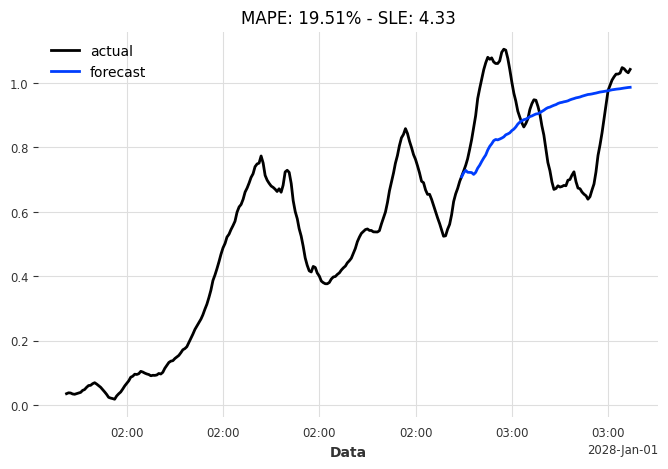

{'p': 12, 'd': 1, 'q': 2, 's': 0}


In [27]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("ARIMA", series_train=["train_filtered_scaled"], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

scaler = Scaler()
train_scaled = scaler.fit_transform(train)
val_scaled = scaler.transform(val)
d_etanol_hid_scaled = scaler.transform(d_etanol_hid)
d_etanol_hid_scaled = d_etanol_hid_scaled.filter()[0]
train_scaled, val_scaled, test_scaled = d_etanol_hid_scaled.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)

model = ARIMA(
    p=best_model['p'],
    d=best_model['d'],
    seasonal_order=(
        0,
        0,
        best_model['q'],
        3
    ),
)
model.fit(train_scaled)
pred_series, mape_arima, sle_arima = eval_model(
    model,
    len(val_scaled),
    d_etanol_hid_scaled.slice(train.start_time(), val.end_time()),
    val_scaled,
    returned = ['PREDICT_VALUES', 'MAPE_VAL', 'SLE_VAL'],
    plot = True,
)
uTheil = UTheil()
u1_arima = uTheil.calculateU1(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
u2_arima = uTheil.calculateU2(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
print(best_model)

### Sem tendência

In [ ]:
scaler = Scaler()
train_scaled = scaler.fit_transform(train_detrend)
val_scaled = scaler.transform(val_detrend)
d_etanol_hid_scaled = scaler.transform(d_etanol_hid_detrend)

model_name = 'ARIMA'
series_train=['train_detrend_scaled']

for p in range(12, 30, 4):
    for d in range(1, 3):
        for q in range(0, 5, 2):
            for s in range(0, 10, 3):
                try:
                    model_run, existing = create_or_get_model_run(
                        model_name=model_name,
                        parametros={                       
                            'p': p,
                            'd': d,
                            'q': q,
                            's': s
                        },
                        series_train=series_train
                    )
                    if existing:
                        continue
                    model = ARIMA(
                        p=p,
                        d=d,
                        seasonal_order=(
                            0,
                            0,
                            q,
                            s
                        ),
                    )
                    model.fit(train_scaled)
                    pred_series, mape_arima, sle_arima = eval_model(
                        model,
                        len(val_scaled),
                        d_etanol_hid_scaled.slice(train.start_time(), val.end_time()),
                        val_scaled,
                        returned = ['PREDICT_VALUES', 'MAPE_VAL', 'SLE_VAL'],
                        plot = False,
                    )
                    uTheil = UTheil()
                    u1_arima = uTheil.calculateU1(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
                    u2_arima = uTheil.calculateU2(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
                    print({
                        'mape': mape_arima,
                        'sle': sle_arima,
                        'u1': u1_arima,
                        'u2': u1_arima,
                        'p': p,
                        'd': d,
                        'q': q,
                        's': s,
                    })
                    metrics = {
                        'mape': mape_arima,
                        'sle': sle_arima,
                        'u1': u1_arima,
                        'u2': u1_arima,
                    }
                    update_model_metrics(model_run, **metrics)
                except:
                    pass

{'mape': np.float64(212.4720243488965), 'sle': np.float64(90.5571482554552), 'u1': np.float64(0.5162831085919465), 'u2': np.float64(0.5162831085919465), 'p': 12, 'd': 1, 'q': 0, 's': 0}
{'mape': np.float64(212.4720243488965), 'sle': np.float64(90.5571482554552), 'u1': np.float64(0.5162831085919465), 'u2': np.float64(0.5162831085919465), 'p': 12, 'd': 1, 'q': 0, 's': 3}
{'mape': np.float64(212.4720243488965), 'sle': np.float64(90.5571482554552), 'u1': np.float64(0.5162831085919465), 'u2': np.float64(0.5162831085919465), 'p': 12, 'd': 1, 'q': 0, 's': 6}
{'mape': np.float64(212.4720243488965), 'sle': np.float64(90.5571482554552), 'u1': np.float64(0.5162831085919465), 'u2': np.float64(0.5162831085919465), 'p': 12, 'd': 1, 'q': 0, 's': 9}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(216.1341642198263), 'sle': np.float64(91.14881379483718), 'u1': np.float64(0.5101140396664884), 'u2': np.float64(0.5101140396664884), 'p': 12, 'd': 1, 'q': 2, 's': 3}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(228.35109726550792), 'sle': np.float64(94.65510999653698), 'u1': np.float64(0.4984364034246259), 'u2': np.float64(0.4984364034246259), 'p': 12, 'd': 1, 'q': 2, 's': 6}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


... (101 outputs left out)

/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(205.02808442253885), 'sle': np.float64(90.26016965454063), 'u1': np.float64(0.5382843417915435), 'u2': np.float64(0.5382843417915435), 'p': 24, 'd': 2, 'q': 2, 's': 9}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(250.2098475406684), 'sle': np.float64(99.64588069326292), 'u1': np.float64(0.47096829062958484), 'u2': np.float64(0.47096829062958484), 'p': 28, 'd': 1, 'q': 0, 's': 9}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


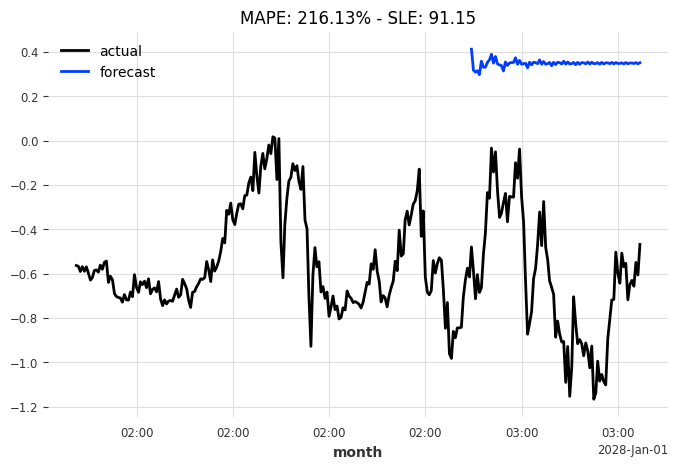

{'p': 12, 'd': 1, 'q': 2, 's': 0}


In [21]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("ARIMA", series_train=["train_detrend_scaled"], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

scaler = Scaler()
train_scaled = scaler.fit_transform(train_detrend)
val_scaled = scaler.transform(val_detrend)
d_etanol_hid_scaled = scaler.transform(d_etanol_hid_detrend)

model = ARIMA(
    p=best_model['p'],
    d=best_model['d'],
    seasonal_order=(
        0,
        0,
        best_model['q'],
        3
    ),
)
model.fit(train_scaled)
pred_series, mape_arima, sle_arima = eval_model(
    model,
    len(val_scaled),
    d_etanol_hid_scaled.slice(train.start_time(), val.end_time()),
    val_scaled,
    returned = ['PREDICT_VALUES', 'MAPE_VAL', 'SLE_VAL'],
    plot = True,
)
uTheil = UTheil()
u1_arima = uTheil.calculateU1(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
u2_arima = uTheil.calculateU2(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
print(best_model)

### Filtrada e sem tendência

In [22]:
scaler = Scaler()
train_scaled = scaler.fit_transform(train_detrend)
val_scaled = scaler.transform(val_detrend)
d_etanol_hid_scaled = scaler.transform(d_etanol_hid_detrend)
d_etanol_hid_scaled = d_etanol_hid_scaled.filter()[0]
train_scaled, val_scaled, test_scaled = d_etanol_hid_scaled.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)

model_name = 'ARIMA'
series_train=['train_detrend_scaled_filtered']

for p in range(12, 30, 4):
    for d in range(1, 3):
        for q in range(0, 5, 2):
            for s in range(0, 10, 3):
                try:
                    model_run, existing = create_or_get_model_run(
                        model_name=model_name,
                        parametros={                       
                            'p': p,
                            'd': d,
                            'q': q,
                            's': s
                        },
                        series_train=series_train
                    )
                    if existing:
                        continue
                    model = ARIMA(
                        p=p,
                        d=d,
                        seasonal_order=(
                            0,
                            0,
                            q,
                            s
                        ),
                    )
                    model.fit(train_scaled)
                    pred_series, mape_arima, sle_arima = eval_model(
                        model,
                        len(val_scaled),
                        d_etanol_hid_scaled.slice(train.start_time(), val.end_time()),
                        val_scaled,
                        returned = ['PREDICT_VALUES', 'MAPE_VAL', 'SLE_VAL'],
                        plot = False,
                    )
                    uTheil = UTheil()
                    u1_arima = uTheil.calculateU1(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
                    u2_arima = uTheil.calculateU2(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
                    print({
                        'mape': mape_arima,
                        'sle': sle_arima,
                        'u1': u1_arima,
                        'u2': u1_arima,
                        'p': p,
                        'd': d,
                        'q': q,
                        's': s,
                    })
                    metrics = {
                        'mape': mape_arima,
                        'sle': sle_arima,
                        'u1': u1_arima,
                        'u2': u1_arima,
                    }
                    update_model_metrics(model_run, **metrics)
                except:
                    pass

{'mape': np.float64(47.9329055065423), 'sle': np.float64(20.986991849914567), 'u1': np.float64(0.2897013403144119), 'u2': np.float64(0.2897013403144119), 'p': 12, 'd': 1, 'q': 0, 's': 0}
{'mape': np.float64(47.9329055065423), 'sle': np.float64(20.986991849914567), 'u1': np.float64(0.2897013403144119), 'u2': np.float64(0.2897013403144119), 'p': 12, 'd': 1, 'q': 0, 's': 3}
{'mape': np.float64(47.9329055065423), 'sle': np.float64(20.986991849914567), 'u1': np.float64(0.2897013403144119), 'u2': np.float64(0.2897013403144119), 'p': 12, 'd': 1, 'q': 0, 's': 6}
{'mape': np.float64(47.9329055065423), 'sle': np.float64(20.986991849914567), 'u1': np.float64(0.2897013403144119), 'u2': np.float64(0.2897013403144119), 'p': 12, 'd': 1, 'q': 0, 's': 9}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(48.659683373154564), 'sle': np.float64(22.990403754053666), 'u1': np.float64(0.32731521667942015), 'u2': np.float64(0.32731521667942015), 'p': 12, 'd': 1, 'q': 2, 's': 3}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(47.17795050500058), 'sle': np.float64(20.57433878052202), 'u1': np.float64(0.2877852219726024), 'u2': np.float64(0.2877852219726024), 'p': 12, 'd': 1, 'q': 2, 's': 6}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:1009: UserWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  warn('Non-invertible starting seasonal moving average'


... (102 outputs left out)

{'mape': np.float64(51.568585434500754), 'sle': np.float64(23.103359064703483), 'u1': np.float64(0.30804165149729185), 'u2': np.float64(0.30804165149729185), 'p': 28, 'd': 2, 'q': 4, 's': 3}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(52.45662564441475), 'sle': np.float64(22.79724210629336), 'u1': np.float64(0.28573111749066404), 'u2': np.float64(0.28573111749066404), 'p': 28, 'd': 2, 'q': 4, 's': 6}
{'mape': np.float64(50.591561100357104), 'sle': np.float64(25.536079487379418), 'u1': np.float64(0.35466405330923395), 'u2': np.float64(0.35466405330923395), 'p': 28, 'd': 2, 'q': 4, 's': 9}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


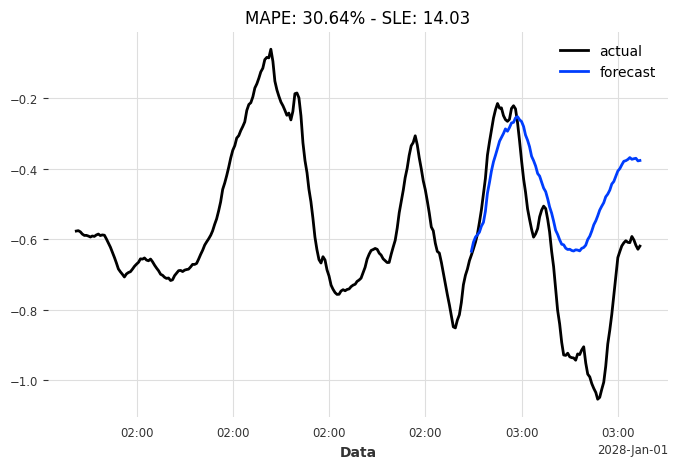

{'p': 28, 'd': 1, 'q': 2, 's': 3}


In [22]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("ARIMA", series_train=["train_detrend_scaled_filtered"], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

scaler = Scaler()
train_scaled = scaler.fit_transform(train_detrend)
val_scaled = scaler.transform(val_detrend)
d_etanol_hid_scaled = scaler.transform(d_etanol_hid_detrend)
d_etanol_hid_scaled = d_etanol_hid_scaled.filter()[0]
train_scaled, val_scaled, test_scaled = d_etanol_hid_scaled.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)

model = ARIMA(
    p=best_model['p'],
    d=best_model['d'],
    seasonal_order=(
        0,
        0,
        best_model['q'],
        best_model['s'],
    ),
)
model.fit(train_scaled)
pred_series, mape_arima, sle_arima = eval_model(
    model,
    len(val_scaled),
    d_etanol_hid_scaled.slice(train.start_time(), val.end_time()),
    val_scaled,
    returned = ['PREDICT_VALUES', 'MAPE_VAL', 'SLE_VAL'],
    plot = True,
)
uTheil = UTheil()
u1_arima = uTheil.calculateU1(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
u2_arima = uTheil.calculateU2(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
print(best_model)

## NARX

### Etanol

In [22]:
from tqdm import tqdm
def pred_values(self, val):
        start_time = val.time_index[0]
        date_freq = val.freq
        if not self.fit_called:
            raise RuntimeError("evaluate() was not called before predict()")
        if type(val) == TimeSeries:
            val = val.univariate_values().tolist()
        else:
            raise ValueError("series must be TimeSeries")
        val = self.window_model.embed_time_series(val)
        val_scaled = self.apply_preprocessing(val.copy())

        if self.random_state is not None:
            torch.manual_seed(self.random_state)
            np.random.seed(self.random_state)

        predicted_outputs = []
        predicted_outputs_original = []

        with tqdm(total=len(val), desc="Prediction") as progress_bar:
            for val_l in val:
                output_original = self.predict_window_with_preprocessing(val_l[0])
                predicted_outputs_original.append(output_original)
                output = self.predict_window_with_preprocessing(val_l[0], False)
                predicted_outputs.append(output)
                progress_bar.update(1)

        predicted_outputs_original = np.array(predicted_outputs_original).flatten()
        return TimeSeries.from_times_and_values(pd.date_range(start=start_time, periods=len(predicted_outputs_original) + self.input_chunk_length, freq=date_freq)[self.input_chunk_length:] ,predicted_outputs_original)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:658: Checkpoint directory /home/ellizeu.sena/Documentos/Mestrado/lightning_logs/version_152/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name    | Type    | Params | Mode 
--------------------------------------------
0 | loss_fn | MSELoss | 0      | train
1 | lin     | Linear  | 3.6 K  | train
2 | lin2    | Linear  | 262 K  | train
3 | lin3    | Linear  | 1.5 K  | train
4 | tanh    | Tanh    | 0      | train
--------------------------------------------
267 K     Trainable params
0         Non-trainable params
267 

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/loops/fit_loop.py:310: The number of training batches (8) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (197 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=200` reached.


Prediction:   0%|          | 0/26 [00:00<?, ?it/s]

Prediction: 100%|██████████| 26/26 [00:00<00:00, 1519.36it/s]


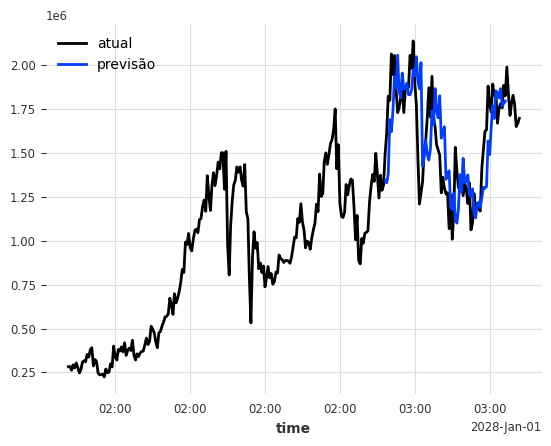

{'mape': 0.11486358593400536, 'sle': np.float64(1.7051234475686443), 'rmse': 225397.9361353283, 'mse': 51659386494.3993, 'u1': np.float64(0.6566406315214249), 'u2': np.float64(0.26274449471387623), 'input_chunk_length': 6, 'output_chunk_length': 3, 'hidden_size': 9, 'batch_size': 3, 'lr': 6}


In [23]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("NARX", series_train=["train_scaled"], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

model = NARX(
    input_chunk_length=best_model['input_chunk_length'],
    output_chunk_length=best_model['output_chunk_length'],
    hidden_size=2**best_model['hidden_size'],
    batch_size=2**best_model['batch_size'],
    n_epochs=200,
    lr=10**(-best_model['lr']),
    preprocessing = [MinMaxScaler()],
    random_state = 0,
)
model.fit(train, val)
metrics = model.evaluate(val)

d_etanol_hid.plot(label='atual')

# Plot da série de previsão
pred = pred_values(model, val)
pred.plot(label='previsão')
plt.show()

print({
    'mape': metrics['mape'],
    'sle': metrics['sle'],
    'rmse': metrics['rmse'],
    'mse': metrics['mse'],
    'u1': metrics['u1'],
    'u2': metrics['u2'],
    **best_model
})


### Etanal + Preço da gasolina

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:658: Checkpoint directory /home/ellizeu.sena/Documentos/Mestrado/lightning_logs/version_152/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name    | Type    | Params | Mode 
--------------------------------------------
0 | loss_fn | MSELoss | 0      | train
1 | lin     | Linear  | 112    | train
2 | lin2    |

Training: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=200` reached.


Prediction:   0%|          | 0/26 [00:00<?, ?it/s]

Prediction: 100%|██████████| 26/26 [00:00<00:00, 1798.20it/s]


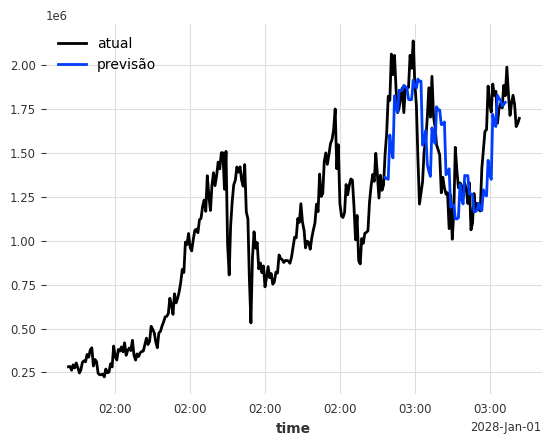

{'mape': 0.12657019693779661, 'sle': np.float64(2.098168705457015), 'rmse': 250684.69277790302, 'mse': 63259275077.309654, 'u1': np.float64(0.7422104963463624), 'u2': np.float64(0.28358171212687117), 'input_chunk_length': 6, 'output_chunk_length': 3, 'hidden_size': 4, 'batch_size': 2, 'lr': 5}


In [24]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("NARX", series_train=['train_p_gasolina_scaled', 'train_scaled'], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

model = NARX(
    input_chunk_length=best_model['input_chunk_length'],
    output_chunk_length=best_model['output_chunk_length'],
    hidden_size=2**best_model['hidden_size'],
    batch_size=2**best_model['batch_size'],
    n_epochs=200,
    lr=10**(-best_model['lr']),
    preprocessing = [MinMaxScaler()],
    random_state = 0,
)
model.fit([train_p_gasolina, train])
metrics = model.evaluate(val)

d_etanol_hid.plot(label='atual')

# Plot da série de previsão
pred = pred_values(model, val)
pred.plot(label='previsão')
plt.show()

print({
    'mape': metrics['mape'],
    'sle': metrics['sle'],
    'rmse': metrics['rmse'],
    'mse': metrics['mse'],
    'u1': metrics['u1'],
    'u2': metrics['u2'],
    **best_model
})


### Etanal + Preço da gasolina (detrend)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:658: Checkpoint directory /home/ellizeu.sena/Documentos/Mestrado/lightning_logs/version_152/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name    | Type    | Params | Mode 
--------------------------------------------
0 | loss_fn | MSELoss | 0      | train
1 | lin     | Linear  | 112    | train
2 | lin2    |

Training: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=200` reached.


Prediction:   0%|          | 0/26 [00:00<?, ?it/s]

Prediction: 100%|██████████| 26/26 [00:00<00:00, 929.20it/s]


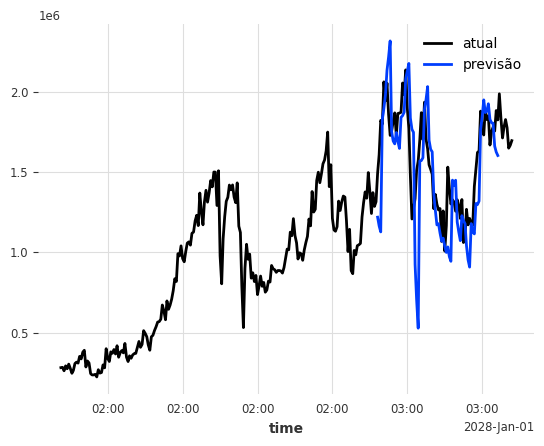

{'mape': 0.1381948621079581, 'sle': np.float64(3.9323867583508916), 'rmse': 274608.26935894525, 'mse': 79959015305.5293, 'u1': np.float64(0.87372168221984), 'u2': np.float64(1.302780710363824), 'input_chunk_length': 6, 'output_chunk_length': 3, 'hidden_size': 4, 'batch_size': 2, 'lr': 5}


In [25]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("NARX", series_train=['train_p_gasolina_detrend_scaled', 'train_detrend_scaled'], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

model = NARX(
    input_chunk_length=best_model['input_chunk_length'],
    output_chunk_length=best_model['output_chunk_length'],
    hidden_size=2**best_model['hidden_size'],
    batch_size=2**best_model['batch_size'],
    n_epochs=200,
    lr=10**(-best_model['lr']),
    preprocessing = [Detrend(),MinMaxScaler()],
    random_state = 0,
)
model.fit([train_p_gasolina, train])
metrics = model.evaluate(val)

d_etanol_hid.plot(label='atual')

# Plot da série de previsão
pred = pred_values(model, val)
pred.plot(label='previsão')
plt.show()

print({
    'mape': metrics['mape'],
    'sle': metrics['sle'],
    'rmse': metrics['rmse'],
    'mse': metrics['mse'],
    'u1': metrics['u1'],
    'u2': metrics['u2'],
    **best_model
})


## DA-RNN

### Etanol

In [19]:
from tqdm import tqdm
def pred_values(self, val):
        start_time = val.time_index[0]
        date_freq = val.freq
        if not self.fit_called:
            raise RuntimeError("evaluate() was not called before predict()")
        if type(val) == TimeSeries:
            val = val.univariate_values().tolist()
        else:
            raise ValueError("series must be TimeSeries")
        val = self.window_model.embed_time_series(val)
        val_scaled = self.apply_preprocessing(val.copy())

        if self.random_state is not None:
            torch.manual_seed(self.random_state)
            np.random.seed(self.random_state)

        predicted_outputs = []
        predicted_outputs_original = []

        with tqdm(total=len(val), desc="Prediction") as progress_bar:
            for val_l in val:
                output_original = self.predict_window_with_preprocessing(val_l[0])
                predicted_outputs_original.append(output_original)
                output = self.predict_window_with_preprocessing(val_l[0], False)
                predicted_outputs.append(output)
                progress_bar.update(1)

        predicted_outputs_original = np.array(predicted_outputs_original).flatten()
        return TimeSeries.from_times_and_values(pd.date_range(start=start_time, periods=len(predicted_outputs_original) + self.input_chunk_length, freq=date_freq)[self.input_chunk_length:] ,predicted_outputs_original)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:658: Checkpoint directory /home/ellizeu.sena/Documentos/Mestrado/lightning_logs/version_156/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name      | Type               | Params | Mode 
---------------------------------------------------------
0 | loss_fn   | MSELoss            | 0      | train
1 | rnn       | LSTM               | 512    | train
2 | attention | MultiheadAttention | 288    | train
3 | fc        | Linear             | 27     | train
---------------------------------------------------------
827       

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/loops/fit_loop.py:310: The number of training batches (4) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (197 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=200` reached.


Prediction:   0%|          | 0/26 [00:00<?, ?it/s]

Prediction: 100%|██████████| 26/26 [00:00<00:00, 1175.52it/s]


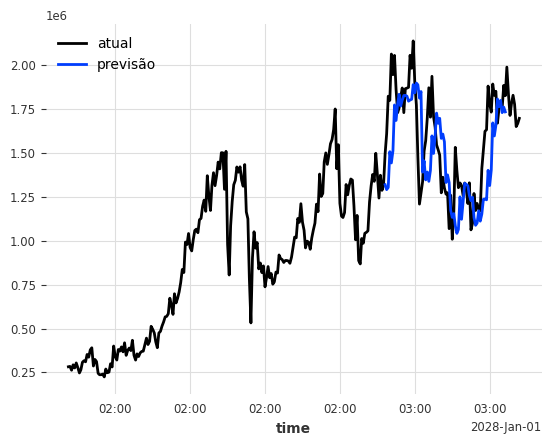

{'mape': 0.12948780108130567, 'sle': np.float64(2.2227922386650167), 'rmse': 255012.49381927564, 'mse': 65394141519.85609, 'u1': np.float64(0.7790869940858488), 'u2': np.float64(0.3463063163145746), 'lr': 0.001, 'input_chunk_length': 6, 'output_chunk_length': 3, 'hidden_size': 8, 'batch_size': 16, 'num_heads_attention': 2, 'dropout': 0.0}


In [20]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("DA-RNN", series_train=["train_scaled"], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

model = DA_RNN(
    input_chunk_length=best_model['input_chunk_length'],
    output_chunk_length=best_model['output_chunk_length'],
    hidden_size=best_model['hidden_size'],
    batch_size=best_model['batch_size'],
    num_heads_attention=best_model['num_heads_attention'],
    dropout=best_model['dropout'],
    n_epochs=200,
    lr=best_model['lr'],
    preprocessing = [MinMaxScaler()],
    random_state = 0
)
model.fit(train, val)
metrics = model.evaluate(val)

d_etanol_hid.plot(label='atual')

# Plot da série de previsão
pred = pred_values(model, val)
pred.plot(label='previsão')
plt.show()

print({
    'mape': metrics['mape'],
    'sle': metrics['sle'],
    'rmse': metrics['rmse'],
    'mse': metrics['mse'],
    'u1': metrics['u1'],
    'u2': metrics['u2'],
    **best_model
})


### Etanal + Preço da gasolina

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:658: Checkpoint directory /home/ellizeu.sena/Documentos/Mestrado/lightning_logs/version_156/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name      | Type               | Params | Mode 
---------------------------------------------------------
0 | loss_fn   | MSELoss            | 0      | train
1 | rnn      

Training: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=200` reached.


Prediction:   0%|          | 0/26 [00:00<?, ?it/s]

Prediction: 100%|██████████| 26/26 [00:00<00:00, 1170.51it/s]


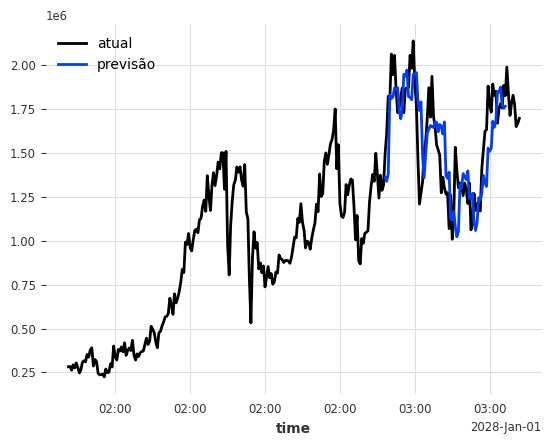

{'mape': 0.11156255477556047, 'sle': np.float64(1.5236577191035516), 'rmse': 206844.16398925838, 'mse': 42861451680.219086, 'u1': np.float64(0.6377428980042497), 'u2': np.float64(0.568717587631542), 'lr': 0.001, 'input_chunk_length': 6, 'output_chunk_length': 3, 'hidden_size': 32, 'batch_size': 16, 'num_heads_attention': 2, 'dropout': 0.0}


In [21]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("DA-RNN", series_train=['train_p_gasolina_scaled', 'train_scaled'], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

model = DA_RNN(
    input_chunk_length=best_model['input_chunk_length'],
    output_chunk_length=best_model['output_chunk_length'],
    hidden_size=best_model['hidden_size'],
    batch_size=best_model['batch_size'],
    num_heads_attention=best_model['num_heads_attention'],
    dropout=best_model['dropout'],
    n_epochs=200,
    lr=best_model['lr'],
    preprocessing = [MinMaxScaler()],
    random_state = 0
)
model.fit([train_p_gasolina, train])
metrics = model.evaluate(val)

d_etanol_hid.plot(label='atual')

# Plot da série de previsão
pred = pred_values(model, val)
pred.plot(label='previsão')
plt.show()

print({
    'mape': metrics['mape'],
    'sle': metrics['sle'],
    'rmse': metrics['rmse'],
    'mse': metrics['mse'],
    'u1': metrics['u1'],
    'u2': metrics['u2'],
    **best_model
})


### Etanal + Preço da gasolina (detrend)

In [48]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("DA-RNN", series_train=['train_p_gasolina_detrend_scaled', 'train_detrend_scaled'], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

model = DA_RNN(
    input_chunk_length=best_model['input_chunk_length'],
    output_chunk_length=best_model['output_chunk_length'],
    hidden_size=best_model['hidden_size'],
    batch_size=best_model['batch_size'],
    num_heads_attention=best_model['num_heads_attention'],
    dropout=best_model['dropout'],
    n_epochs=200,
    lr=best_model['lr'],
    preprocessing = [MinMaxScaler()],
    random_state = 0
)
model.fit([train_p_gasolina, train])
metrics = model.evaluate(val)

d_etanol_hid.plot(label='atual')

# Plot da série de previsão
pred = pred_values(model, val)
pred.plot(label='previsão')
plt.show()

print({
    'mape': metrics['mape'],
    'sle': metrics['sle'],
    'rmse': metrics['rmse'],
    'mse': metrics['mse'],
    'u1': metrics['u1'],
    'u2': metrics['u2'],
    **best_model
})


AttributeError: 'NoneType' object has no attribute 'parametros'